# Three-Qubit Bit-Flip Repetition Code

This notebook implements the **three-qubit bit-flip repetition code**, a foundational quantum error-correcting code capable of detecting and correcting a single bit-flip ($X$) error.

## Encoding
A single logical qubit $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ is encoded across three physical data qubits using the basis states:

$$|0_L\rangle = |000\rangle$$

$$|1_L\rangle = |111\rangle$$

This maps the arbitrary logical state to:

$$|\psi_L\rangle = \alpha|000\rangle + \beta|111\rangle$$

## Error Detection & Recovery
Because directly measuring the data qubits would collapse the superposition $\alpha|000\rangle + \beta|111\rangle$, error detection relies on **syndrome extraction**:
1. **Parity Checks:** Two ancilla qubits measure the parity stabilizers $Z_0 Z_1$ and $Z_1 Z_2$ to locate where a bit flip occurred without revealing the logical state.
2. **Correction:** Based on the two-bit syndrome outcome, a targeted $X$ gate flips the erroneous qubit back to restore $|\psi_L\rangle$.


In [1]:
# Setup for rest of the notebook

# Easier way to work with files and directories
from pathlib import Path

# Creates plots and figures
import matplotlib.pyplot as plt
# Provides arrays and numerical operations
import numpy as np
import pandas as pd

# Core Qiskit imports
from qiskit import ClassicalRegister
from qiskit import QuantumCircuit
from qiskit import QuantumRegister
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram

from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.noise import pauli_error

# Reproducibility constants
# A shot is one execution and measurement of a circuit, more shots generally reduce sampling uncertainty. I chose 4096 because powers of 2 are easier to work with (like calculating standard error) and will not take too long to calculate.
# The seed makes pseudo-random behaviour reproducible, and 42 is a commonly used value that can I chose for consistency
SHOTS = 4096
SEED = 42

# Project directories for windows. Script exist for MacBook conversion.
PROJECT_DIR = Path(r"C:\Users\Karthi\Qauntum")
FIGURE_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(f"Project directory: {PROJECT_DIR}")
print("Environment ready.")

Project directory: C:\Users\Karthi\Qauntum
Environment ready.


In [2]:
# Reusable execution function
# circuit - Qiskit QuantumCircuit to execute
# shots=SHOTS - one independent execution of the circuit followed by measurement
# noise_model=None - optional noise model that we will not be using
# seed=SEED - pseudo-random behaviour, making results reproducible
# optimization_level (int) - Transpiler optimization level (0 preserves redundant gates required for quantum error-correction circuits).
# Returns - dict[str, int]: Bitstring measurement outcomes mapped to their observed counts
def run_counts(
    circuit,
    shots=SHOTS,
    noise_model=None,
    seed=SEED,
    optimization_level=0,
):
    # Compile and execute a measured Qiskit circuit
    # Initialize the Aer simulator backend with optional noise and a fixed RNG seed
    simulator = AerSimulator(
        noise_model=noise_model,
        seed_simulator=seed,
    )

    # transpile() step converts it into a form compatible with the selected simulator
    # optimization_level=0 prevents the compiler from simplifying away redundant QEC gates
    compiled_circuit = transpile(
        circuit,
        simulator,
        optimization_level=optimization_level,
        seed_transpiler=seed,
    )

    # Execute the compiled circuit and retrieve the job result
    result = simulator.run(
        compiled_circuit,
        shots=shots,
    ).result()

    # Returns the measurement counts
    return result.get_counts()
# We use optimization_level=0 because later cells will attach noise to specific gates
# This reduces the chance that transpilation changes or removes an instruction we want to study

## Logical Encoding

The three-qubit repetition code uses three physical data qubits to encode one logical state. The logical basis states (codewords) are:

$$|0_L\rangle = |000\rangle, \qquad |1_L\rangle = |111\rangle$$

An arbitrary single-qubit state $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ is encoded into an entangled three-qubit state using two CNOT gates:

$$|\psi_L\rangle = \alpha|000\rangle + \beta|111\rangle$$

### Majority-Voting Recovery
If at most one physical qubit undergoes a bit-flip ($X$) error, the original logical value can be uniquely identified via majority voting:

| Logical $0$ States | Decoded Value | Logical $1$ States | Decoded Value |
| :---: | :---: | :---: | :---: |
| $\|000\rangle$ *(no error)* | $0$ | $\|111\rangle$ *(no error)* | $1$ |
| $\|001\rangle$ *(qubit 0 flipped)* | $0$ | $\|110\rangle$ *(qubit 0 flipped)* | $1$ |
| $\|010\rangle$ *(qubit 1 flipped)* | $0$ | $\|101\rangle$ *(qubit 1 flipped)* | $1$ |
| $\|100\rangle$ *(qubit 2 flipped)* | $0$ | $\|011\rangle$ *(qubit 2 flipped)* | $1$ |

*(Note: Qubit indexing follows Qiskit's little-endian convention $|q_2 q_1 q_0\rangle$.)*

### Scope and Limitations
While this code protects against single **bit-flip ($X$) errors**, it cannot detect or correct **phase-flip ($Z$) errors** (which map $\alpha|000\rangle + \beta|111\rangle \to \alpha|000\rangle - \beta|111\rangle$). Protecting an arbitrary quantum state against both $X$ and $Z$ errors requires larger codes such as the **9-qubit Shor code**, **7-qubit Steane code**, or **surface codes**.


In [3]:
# Reusable encoding function
# Arguments:
# circuit (QuantumCircuit): Quantum circuit to append the encoding gates to
# data_qubits (Sequence[Qubit] | QuantumRegister): Three physical data qubits, where data_qubits[0] holds the initial state to be encoded
# Raises:
# ValueError: If data_qubits does not contain exactly three qubits
def encode_repetition_code(circuit, data_qubits):

    # Encode the state of data_qubits[0] into a
    # three-qubit bit-flip repetition code.
    #
    # |0> -> |000>
    # |1> -> |111>

    # Ensure exactly three physical data qubits are supplied for the distance-3 code
    if len(data_qubits) != 3:
        raise ValueError(
            "The repetition code requires exactly "
            "three data qubits."
        )

    # Copy the computational basis state of data_qubits[0] onto data_qubits[1] and [2] via CNOT gates (assuming target qubits start in |0>)
    circuit.cx(
        data_qubits[0],
        data_qubits[1],
    )

    circuit.cx(
        data_qubits[0],
        data_qubits[2],
    )


In [4]:
# Encode logical zero
# Initialize a 3-qubit, 3-classical-bit circuit (qubits default to |000>, representing logical |0>)
logical_zero_circuit = QuantumCircuit(3, 3)

# Encode qubit 0 into the three-qubit logical |0_L> = |000> codeword
encode_repetition_code(
    logical_zero_circuit,
    [0, 1, 2],
)

# Add a visual and transpiler barrier to separate encoding from measurement
logical_zero_circuit.barrier()
# Measure all three physical data qubits into the corresponding classical bits
logical_zero_circuit.measure(
    [0, 1, 2],
    [0, 1, 2],
)
# Print an ASCII diagram of the constructed circuit
print(logical_zero_circuit.draw())

                ░ ┌─┐      
q_0: ──■────■───░─┤M├──────
     ┌─┴─┐  │   ░ └╥┘┌─┐   
q_1: ┤ X ├──┼───░──╫─┤M├───
     └───┘┌─┴─┐ ░  ║ └╥┘┌─┐
q_2: ─────┤ X ├─░──╫──╫─┤M├
          └───┘ ░  ║  ║ └╥┘
c: 3/══════════════╩══╩══╩═
                   0  1  2 


In [5]:
# Run the circuit and collect measurement counts
logical_zero_counts = run_counts(
    logical_zero_circuit
)

print("Logical |0> counts:")
print(logical_zero_counts)

# Verify all shots collapsed to |000>
assert logical_zero_counts == {
    "000": SHOTS
}

print("Logical |0> was encoded successfully.")

Logical |0> counts:
{'000': 4096}
Logical |0> was encoded successfully.


In [6]:
# Encode logical one
# Initialize a 3-qubit, 3-classical-bit circuit
logical_one_circuit = QuantumCircuit(3, 3)

# Prepare the original information qubit in |1>.
logical_one_circuit.x(0)

# Encode into the logical |1_L> = |111> state
encode_repetition_code(
    logical_one_circuit,
    [0, 1, 2],
)

# Separate encoding from measurement
logical_one_circuit.barrier()

# Measure all data qubits into classical bits
logical_one_circuit.measure(
    [0, 1, 2],
    [0, 1, 2],
)

# Print the circuit diagram
print(logical_one_circuit.draw())

     ┌───┐           ░ ┌─┐      
q_0: ┤ X ├──■────■───░─┤M├──────
     └───┘┌─┴─┐  │   ░ └╥┘┌─┐   
q_1: ─────┤ X ├──┼───░──╫─┤M├───
          └───┘┌─┴─┐ ░  ║ └╥┘┌─┐
q_2: ──────────┤ X ├─░──╫──╫─┤M├
               └───┘ ░  ║  ║ └╥┘
c: 3/═══════════════════╩══╩══╩═
                        0  1  2 


In [7]:
# Run the circuit and collect measurement counts
logical_one_counts = run_counts(
    logical_one_circuit
)

print("Logical |1> counts:")
print(logical_one_counts)

# Verify all shots collapsed to |111>
assert logical_one_counts == {
    "111": SHOTS
}

print("Logical |1> was encoded successfully.")

Logical |1> counts:
{'111': 4096}
Logical |1> was encoded successfully.


In [8]:
# Compare the logical states
# Plot measurement histograms for logical |0> and |1>
logical_state_figure = plot_histogram(
    [
        logical_zero_counts,
        logical_one_counts,
    ],
    legend=[
        "Logical |0>",
        "Logical |1>",
    ],
    title="Three-qubit repetition-code states",
)

# Define output file path and save the figure
logical_state_figure_path = (
    FIGURE_DIR
    / "repetition_code_logical_states.png"
)

logical_state_figure.savefig(
    logical_state_figure_path,
    dpi=200,
    bbox_inches="tight",
)

print(
    f"Saved figure to: "
    f"{logical_state_figure_path}"
)

Saved figure to: C:\Users\Karthi\Qauntum\figures\repetition_code_logical_states.png


In [9]:
# Inspect the logical-state vectors
# Initialize a 3-qubit circuit (without classical bits) for exact statevector simulation
logical_zero_state_circuit = QuantumCircuit(3)

# Encode qubit 0 into logical |0_L> = |000>
encode_repetition_code(
    logical_zero_state_circuit,
    [0, 1, 2],
)

# Compute the exact quantum statevector
logical_zero_state = Statevector.from_instruction(
    logical_zero_state_circuit
)

# Print exact basis state probabilities
print("Logical |0> state:")
print(
    logical_zero_state.probabilities_dict()
)

Logical |0> state:
{np.str_('000'): np.float64(1.0)}


In [10]:
# Inspect the logical-state vectors
# Initialize a 3-qubit circuit for exact statevector simulation
logical_one_state_circuit = QuantumCircuit(3)

# Prepare qubit 0 in |1>
logical_one_state_circuit.x(0)

# Encode into logical |1_L> = |111>
encode_repetition_code(
    logical_one_state_circuit,
    [0, 1, 2],
)

# Compute the exact quantum statevector
logical_one_state = Statevector.from_instruction(
    logical_one_state_circuit
)

# Print exact basis state probabilities
print("Logical |1> state:")
print(
    logical_one_state.probabilities_dict()
)

Logical |1> state:
{np.str_('111'): np.float64(1.0)}


## Deterministic single-qubit errors

A bit-flip error is represented by the Pauli X operation. To verify the code's behaviour, a known X error is inserted on each data qubit in turn.

Because Qiskit displays classical bit strings in descending bit-index order, an error on qubit 0 appears as the rightmost changed bit.

In [11]:
# Reusable circuit function
def create_encoded_measurement_circuit(
    logical_value=0,
    error_qubit=None,
):

    # Create and measure a three-qubit repetition-code circuit with an optional deterministic X error

    # Validate logical value and error qubit index
    if logical_value not in (0, 1):
        raise ValueError(
            "logical_value must be 0 or 1."
        )

    if error_qubit not in (None, 0, 1, 2):
        raise ValueError(
            "error_qubit must be None, 0, 1 or 2."
        )

    circuit = QuantumCircuit(3, 3)

    # Prepare initial |1> state if encoding logical 1
    if logical_value == 1:
        circuit.x(0)

    # Encode across all three data qubits
    encode_repetition_code(
        circuit,
        [0, 1, 2],
    )

    circuit.barrier()

    # Inject a single deterministic bit-flip (X) error if specified
    if error_qubit is not None:
        circuit.x(error_qubit)

    circuit.barrier()
    # Measure all three data qubits
    circuit.measure(
        [0, 1, 2],
        [0, 1, 2],
    )

    return circuit

In [12]:
# Test each possible single-qubit error
single_error_results = []

# Test logical |0> under no error and each single-qubit bit flip
for error_qubit in [None, 0, 1, 2]:
    circuit = create_encoded_measurement_circuit(
        logical_value=0,
        error_qubit=error_qubit,
    )

    # Run simulation and extract the dominant measurement outcome
    counts = run_counts(circuit)

    measured_state = max(
        counts,
        key=counts.get,
    )

    # Record experiment parameters and outcome
    single_error_results.append(
        {
            "logical_value": 0,
            "error_qubit": (
                "none"
                if error_qubit is None
                else error_qubit
            ),
            "measured_state": measured_state,
            "shots": SHOTS,
        }
    )

    print(
        f"Error qubit: {error_qubit} | "
        f"Measured state: {measured_state}"
    )

Error qubit: None | Measured state: 000
Error qubit: 0 | Measured state: 001
Error qubit: 1 | Measured state: 010
Error qubit: 2 | Measured state: 100


In [13]:
# Display table
single_error_df = pd.DataFrame(
    single_error_results
)

single_error_df

,logical_value,error_qubit,measured_state,shots
0,0,none,000,4096
1,0,0,001,4096
2,0,1,010,4096
3,0,2,100,4096


In [14]:
# Implement majority-vote decoding

# Decode a three-bit repetition-code measurement.
#
# Returns logical 0 when a majority of bits are zero,
# and logical 1 when a majority are one.
def majority_vote_decode(bit_string):

    if len(bit_string) != 3:
        raise ValueError(
            "Expected a three-character bit string."
        )

    if any(
        bit not in {"0", "1"}
        for bit in bit_string
    ):
        raise ValueError(
            "Bit string must contain only 0 and 1."
        )

    number_of_ones = bit_string.count("1")

    return 1 if number_of_ones >= 2 else 0

In [15]:
# Test every three-bit pattern
test_bit_strings = [
    "000",
    "001",
    "010",
    "100",
    "111",
    "110",
    "101",
    "011",
]

for bit_string in test_bit_strings:
    decoded_value = majority_vote_decode(
        bit_string
    )

    print(
        f"{bit_string} -> "
        f"logical {decoded_value}"
    )

000 -> logical 0
001 -> logical 0
010 -> logical 0
100 -> logical 0
111 -> logical 1
110 -> logical 1
101 -> logical 1
011 -> logical 1


In [16]:
# Verify recovery from every single error
for result in single_error_results:
    decoded_value = majority_vote_decode(
        result["measured_state"]
    )

    result["decoded_value"] = decoded_value
    result["decoding_successful"] = (
        decoded_value
        == result["logical_value"]
    )

single_error_df = pd.DataFrame(
    single_error_results
)

single_error_df

,logical_value,error_qubit,measured_state,shots,decoded_value,decoding_successful
0,0,none,000,4096,0,True
1,0,0,001,4096,0,True
2,0,1,010,4096,0,True
3,0,2,100,4096,0,True


In [17]:
# Assert that all cases recover a logical zero
assert single_error_df[
    "decoding_successful"
].all()

print(
    "Majority-vote decoding corrected every single-qubit bit-flip case."
)

Majority-vote decoding corrected every single-qubit bit-flip case.


In [18]:
# Repeat for logical one
logical_one_error_results = []

for error_qubit in [None, 0, 1, 2]:
    circuit = create_encoded_measurement_circuit(
        logical_value=1,
        error_qubit=error_qubit,
    )

    counts = run_counts(circuit)

    measured_state = max(
        counts,
        key=counts.get,
    )

    decoded_value = majority_vote_decode(
        measured_state
    )

    logical_one_error_results.append(
        {
            "logical_value": 1,
            "error_qubit": (
                "none"
                if error_qubit is None
                else error_qubit
            ),
            "measured_state": measured_state,
            "decoded_value": decoded_value,
            "decoding_successful": (
                decoded_value == 1
            ),
        }
    )

logical_one_error_df = pd.DataFrame(
    logical_one_error_results
)

logical_one_error_df

,logical_value,error_qubit,measured_state,decoded_value,decoding_successful
0,1,none,111,1,True
1,1,0,110,1,True
2,1,1,101,1,True
3,1,2,011,1,True


In [19]:
assert logical_one_error_df[
    "decoding_successful"
].all()

print(
    "Majority-vote decoding recovered logical one from every single-qubit bit flip."
)

Majority-vote decoding recovered logical one from every single-qubit bit flip.


In [20]:
# Save the initial results
combined_error_results = pd.concat(
    [
        single_error_df,
        logical_one_error_df,
    ],
    ignore_index=True,
)

initial_results_path = (
    RESULTS_DIR
    / "repetition_code_single_errors.csv"
)

combined_error_results.to_csv(
    initial_results_path,
    index=False,
)

print(
    f"Saved results to: "
    f"{initial_results_path}"
)

combined_error_results

Saved results to: C:\Users\Karthi\Qauntum\results\repetition_code_single_errors.csv


,logical_value,error_qubit,measured_state,shots,decoded_value,decoding_successful
0,0,none,000,4096.0,0,True
1,0,0,001,4096.0,0,True
2,0,1,010,4096.0,0,True
3,0,2,100,4096.0,0,True
4,1,none,111,NaN,1,True
5,1,0,110,NaN,1,True
6,1,1,101,NaN,1,True
7,1,2,011,NaN,1,True


### Initial Repetition-Code Results

The three-qubit repetition code successfully encoded logical zero as $\lvert 0_L \rangle = \lvert 000 \rangle$ and logical one as $\lvert 1_L \rangle = \lvert 111 \rangle$. Applying a single $X$ error flipped one physical bit ($\lvert 000 \rangle \to \{\lvert 001 \rangle, \lvert 010 \rangle, \lvert 100 \rangle\}$) but did not change the logical value recovered by majority-vote decoding.

The measured bit-string position reflects Qiskit's little-endian display convention ($\lvert q_2 q_1 q_0 \rangle$). An $X$ error on qubit $q_0$ therefore appears in the rightmost bit, while an error on qubit $q_2$ appears in the leftmost bit.

Majority voting can recover the logical value after measurement, but this is not yet a complete quantum error-correction procedure. Directly measuring all three data qubits collapses any encoded quantum superposition ($\alpha\lvert 000 \rangle + \beta\lvert 111 \rangle$). A true syndrome-extraction circuit instead uses ancilla qubits to measure parity relationships ($Z_0 Z_1$ and $Z_1 Z_2$) between data qubits without revealing or collapsing the encoded logical state.

The next stage will introduce two ancilla qubits ($a_0, a_1$) and construct syndrome measurements that identify which physical qubit experienced a bit-flip error.


# Error-Syndrome Extraction

A repetition-code syndrome identifies changes in parity between neighbouring data qubits ($q_0, q_1, q_2$).

The parity checks are:

$$s_0 = q_0 \oplus q_1$$

$$s_1 = q_1 \oplus q_2$$

Two ancilla qubits store these parity values. Measuring the ancillas reveals which data qubit experienced a bit-flip ($X$) error without directly measuring the encoded logical value ($\lvert 0_L \rangle = \lvert 000 \rangle$ or $\lvert 1_L \rangle = \lvert 111 \rangle$).

The syndrome is displayed by Qiskit as $s_1s_0$ because classical bit strings are ordered from the highest classical-bit index to the lowest (little-endian convention).



In [21]:
# Define named registers for easy understanding
data_register = QuantumRegister(
    3,
    name="data",
)

ancilla_register = QuantumRegister(
    2,
    name="ancilla",
)

syndrome_register = ClassicalRegister(
    2,
    name="syndrome",
)

In [22]:
# Syndrome-extraction function
# Extract the two parity checks of the three-qubit repetition code.
#
# ancilla_qubits[0] measures q0 XOR q1.
# ancilla_qubits[1] measures q1 XOR q2.
def extract_repetition_syndrome(
    circuit,
    data_qubits,
    ancilla_qubits,
):

    if len(data_qubits) != 3:
        raise ValueError(
            "Exactly three data qubits are required."
        )

    if len(ancilla_qubits) != 2:
        raise ValueError(
            "Exactly two ancilla qubits are required."
        )

    # First parity check: q0 XOR q1.
    circuit.cx(
        data_qubits[0],
        ancilla_qubits[0],
    )

    circuit.cx(
        data_qubits[1],
        ancilla_qubits[0],
    )

    # Second parity check: q1 XOR q2.
    circuit.cx(
        data_qubits[1],
        ancilla_qubits[1],
    )

    circuit.cx(
        data_qubits[2],
        ancilla_qubits[1],
    )

In [23]:
# Complete syndrome circuit
# Encode a logical value, inject an optional X error, extract the repetition-code syndrome, and measure only the syndrome ancillas
def create_syndrome_circuit(
    logical_value=0,
    error_qubit=None,
):


    if logical_value not in (0, 1):
        raise ValueError(
            "logical_value must be 0 or 1."
        )

    if error_qubit not in (None, 0, 1, 2):
        raise ValueError(
            "error_qubit must be None, 0, 1 or 2."
        )

    data = QuantumRegister(
        3,
        name="data",
    )

    ancilla = QuantumRegister(
        2,
        name="ancilla",
    )

    syndrome = ClassicalRegister(
        2,
        name="syndrome",
    )

    circuit = QuantumCircuit(
        data,
        ancilla,
        syndrome,
    )

    # Prepare the original logical value.
    if logical_value == 1:
        circuit.x(data[0])

    # Encode it across the three data qubits.
    encode_repetition_code(
        circuit,
        [
            data[0],
            data[1],
            data[2],
        ],
    )

    circuit.barrier()

    # Insert a deterministic physical X error.
    if error_qubit is not None:
        circuit.x(
            data[error_qubit]
        )

    circuit.barrier()

    # Extract parity information into the ancillas.
    extract_repetition_syndrome(
        circuit,
        [
            data[0],
            data[1],
            data[2],
        ],
        [
            ancilla[0],
            ancilla[1],
        ],
    )

    circuit.barrier()

    # Measure only the ancillas.
    circuit.measure(
        ancilla[0],
        syndrome[0],
    )

    circuit.measure(
        ancilla[1],
        syndrome[1],
    )

    return circuit

In [24]:
# Testing the no-error syndrome
no_error_syndrome_circuit = (
    create_syndrome_circuit(
        logical_value=0,
        error_qubit=None,
    )
)

print(
    no_error_syndrome_circuit.draw(
        output="text"
    )
)

                       ░  ░                      ░       
    data_0: ──■────■───░──░───■──────────────────░───────
            ┌─┴─┐  │   ░  ░   │                  ░       
    data_1: ┤ X ├──┼───░──░───┼────■────■────────░───────
            └───┘┌─┴─┐ ░  ░   │    │    │        ░       
    data_2: ─────┤ X ├─░──░───┼────┼────┼────■───░───────
                 └───┘ ░  ░ ┌─┴─┐┌─┴─┐  │    │   ░ ┌─┐   
 ancilla_0: ───────────░──░─┤ X ├┤ X ├──┼────┼───░─┤M├───
                       ░  ░ └───┘└───┘┌─┴─┐┌─┴─┐ ░ └╥┘┌─┐
 ancilla_1: ───────────░──░───────────┤ X ├┤ X ├─░──╫─┤M├
                       ░  ░           └───┘└───┘ ░  ║ └╥┘
syndrome: 2/════════════════════════════════════════╩══╩═
                                                    0  1 


In [25]:
# Run
no_error_syndrome_counts = run_counts(
    no_error_syndrome_circuit
)

print(
    "No-error syndrome counts:",
    no_error_syndrome_counts,
)

assert no_error_syndrome_counts == {
    "00": SHOTS
}

print(
    "No error correctly produced syndrome 00."
)

No-error syndrome counts: {'00': 4096}
No error correctly produced syndrome 00.


In [26]:
# Test errors on each physical qubit
syndrome_test_results = []

for error_qubit in [
    None,
    0,
    1,
    2,
]:
    syndrome_circuit = create_syndrome_circuit(
        logical_value=0,
        error_qubit=error_qubit,
    )

    syndrome_counts = run_counts(
        syndrome_circuit
    )

    measured_syndrome = max(
        syndrome_counts,
        key=syndrome_counts.get,
    )

    syndrome_test_results.append(
        {
            "logical_value": 0,
            "error_qubit": (
                "none"
                if error_qubit is None
                else error_qubit
            ),
            "measured_syndrome": (
                measured_syndrome
            ),
            "counts": syndrome_counts,
        }
    )

    print(
        f"Error qubit: {str(error_qubit):>4} | "
        f"Syndrome: {measured_syndrome} | "
        f"Counts: {syndrome_counts}"
    )

Error qubit: None | Syndrome: 00 | Counts: {'00': 4096}
Error qubit:    0 | Syndrome: 01 | Counts: {'01': 4096}
Error qubit:    1 | Syndrome: 11 | Counts: {'11': 4096}
Error qubit:    2 | Syndrome: 10 | Counts: {'10': 4096}


In [27]:
# Decoder lookup table
SYNDROME_TO_ERROR_QUBIT = {
    "00": None,
    "01": 0,
    "11": 1,
    "10": 2,
}

In [28]:
# Decoder

# Return the data-qubit index identified by a two-bit repetition-code syndrome
#
# Returns None when the syndrome indicates no error
def decode_repetition_syndrome(
    syndrome,
):

    if syndrome not in SYNDROME_TO_ERROR_QUBIT:
        raise ValueError(
            f"Invalid syndrome: {syndrome}"
        )

    return SYNDROME_TO_ERROR_QUBIT[
        syndrome
    ]

In [29]:
# Test all syndromes
for syndrome in [
    "00",
    "01",
    "11",
    "10",
]:
    identified_qubit = (
        decode_repetition_syndrome(
            syndrome
        )
    )

    print(
        f"Syndrome {syndrome} -> "
        f"error qubit {identified_qubit}"
    )

Syndrome 00 -> error qubit None
Syndrome 01 -> error qubit 0
Syndrome 11 -> error qubit 1
Syndrome 10 -> error qubit 2


In [30]:
# Verify every deterministic error
for result in syndrome_test_results:
    measured_syndrome = result[
        "measured_syndrome"
    ]

    identified_qubit = (
        decode_repetition_syndrome(
            measured_syndrome
        )
    )

    expected_qubit = result[
        "error_qubit"
    ]

    if expected_qubit == "none":
        expected_qubit = None

    result["identified_error_qubit"] = (
        identified_qubit
    )

    result["syndrome_correct"] = (
        identified_qubit
        == expected_qubit
    )

In [31]:
syndrome_test_df = pd.DataFrame(
    syndrome_test_results
)

syndrome_test_df


,logical_value,error_qubit,measured_syndrome,counts,identified_error_qubit,syndrome_correct
0,0,none,00,{'00': 4096},NaN,True
1,0,0,01,{'01': 4096},0.0,True
2,0,1,11,{'11': 4096},1.0,True
3,0,2,10,{'10': 4096},2.0,True


In [32]:
assert syndrome_test_df[
    "syndrome_correct"
].all()

print(
    "Every deterministic single-qubit error "
    "was identified correctly."
)

Every deterministic single-qubit error was identified correctly.


In [33]:
# Verify that the syndrome does not reveal the logical value
logical_value_syndrome_results = []

for logical_value in [
    0,
    1,
]:
    circuit = create_syndrome_circuit(
        logical_value=logical_value,
        error_qubit=None,
    )

    counts = run_counts(
        circuit
    )

    measured_syndrome = max(
        counts,
        key=counts.get,
    )

    logical_value_syndrome_results.append(
        {
            "logical_value": logical_value,
            "error_qubit": "none",
            "syndrome": measured_syndrome,
            "counts": counts,
        }
    )

    print(
        f"Logical value: {logical_value} | "
        f"Syndrome: {measured_syndrome}"
    )

Logical value: 0 | Syndrome: 00
Logical value: 1 | Syndrome: 00


In [34]:
assert all(
    result["syndrome"] == "00"
    for result
    in logical_value_syndrome_results
)

print(
    "The no-error syndrome is independent of the encoded logical value."
)

The no-error syndrome is independent of the encoded logical value.


In [35]:
# Test every error for both logical values
complete_syndrome_results = []

for logical_value in [
    0,
    1,
]:
    for error_qubit in [
        None,
        0,
        1,
        2,
    ]:
        circuit = create_syndrome_circuit(
            logical_value=logical_value,
            error_qubit=error_qubit,
        )

        counts = run_counts(
            circuit
        )

        measured_syndrome = max(
            counts,
            key=counts.get,
        )

        identified_qubit = (
            decode_repetition_syndrome(
                measured_syndrome
            )
        )

        complete_syndrome_results.append(
            {
                "logical_value": logical_value,
                "error_qubit": (
                    "none"
                    if error_qubit is None
                    else error_qubit
                ),
                "measured_syndrome": (
                    measured_syndrome
                ),
                "identified_error_qubit": (
                    "none"
                    if identified_qubit is None
                    else identified_qubit
                ),
                "shots": SHOTS,
            }
        )

In [36]:
complete_syndrome_df = pd.DataFrame(
    complete_syndrome_results
)

complete_syndrome_df

,logical_value,error_qubit,measured_syndrome,identified_error_qubit,shots
0,0,none,00,none,4096
1,0,0,01,0,4096
2,0,1,11,1,4096
3,0,2,10,2,4096
4,1,none,00,none,4096
5,1,0,01,0,4096
6,1,1,11,1,4096
7,1,2,10,2,4096


In [37]:
# Validation
expected_syndromes = {
    "none": "00",
    0: "01",
    1: "11",
    2: "10",
}

for result in complete_syndrome_results:
    error_qubit = result["error_qubit"]

    expected_syndrome = (
        expected_syndromes[
            error_qubit
        ]
    )

    assert (
        result["measured_syndrome"]
        == expected_syndrome
    )

print(
    "Syndromes were correct for both "
    "logical codewords."
)

Syndromes were correct for both logical codewords.


In [38]:
# Plot the syndrome outcomes
syndrome_plot_data = {}

for error_qubit in [
    None,
    0,
    1,
    2,
]:
    circuit = create_syndrome_circuit(
        logical_value=0,
        error_qubit=error_qubit,
    )

    counts = run_counts(
        circuit
    )

    label = (
        "No error"
        if error_qubit is None
        else f"Error on q{error_qubit}"
    )

    syndrome_plot_data[label] = counts

In [39]:
# Histogram
syndrome_figure = plot_histogram(
    list(
        syndrome_plot_data.values()
    ),
    legend=list(
        syndrome_plot_data.keys()
    ),
    title=(
        "Repetition-code syndromes "
        "for deterministic X errors"
    ),
)

syndrome_figure_path = (
    FIGURE_DIR
    / "repetition_code_syndromes.png"
)

syndrome_figure.savefig(
    syndrome_figure_path,
    dpi=200,
    bbox_inches="tight",
)

print(
    f"Saved figure to: "
    f"{syndrome_figure_path}"
)

Saved figure to: C:\Users\Karthi\Qauntum\figures\repetition_code_syndromes.png


In [40]:
# Save the results
syndrome_results_path = (
    RESULTS_DIR
    / "repetition_code_syndromes.csv"
)

complete_syndrome_df.to_csv(
    syndrome_results_path,
    index=False,
)

print(
    f"Saved results to: "
    f"{syndrome_results_path}"
)

Saved results to: C:\Users\Karthi\Qauntum\results\repetition_code_syndromes.csv


## Syndrome-Extraction Results

The two ancilla qubits measured the parity checks $s_0 = q_0 \oplus q_1$ and $s_1 = q_1 \oplus q_2$. Each possible single-qubit bit flip ($X_i$) produced a distinct two-bit syndrome $s_1 s_0$:

- No error ($I$) produced $00$.
- An error on $q_0$ ($X_0$) produced $01$.
- An error on $q_1$ ($X_1$) produced $11$.
- An error on $q_2$ ($X_2$) produced $10$.

The displayed ordering is $s_1 s_0$ because Qiskit displays classical bits from the highest index to the lowest (little-endian convention).

Logical zero ($\lvert 0_L \rangle = \lvert 000 \rangle$) and logical one ($\lvert 1_L \rangle = \lvert 111 \rangle$) produced the same no-error syndrome ($00$). This demonstrates that the stabiliser parity measurements ($Z_0 Z_1$ and $Z_1 Z_2$) identify disagreements between physical qubits without revealing the encoded logical value.

Only the ancilla qubits ($a_0, a_1$) were measured in this experiment. The data qubits ($q_0, q_1, q_2$) were not directly measured during syndrome extraction. This is important because directly measuring the data qubits would reveal and collapse an encoded superposition ($\alpha\lvert 0_L \rangle + \beta\lvert 1_L \rangle$).

The current circuits identify deterministic $X$ errors but do not yet apply a correction. The next stage will connect each measured syndrome $s_1 s_0$ to the appropriate recovery operation ($X_i$) and verify that the encoded logical state is restored.


# Syndrome-Controlled Correction

After syndrome extraction, the two ancilla qubits ($a_0, a_1$) contain enough information to identify any single-qubit bit-flip ($X$) error.

The recovery rules ($s_1 s_0 \mapsto \text{recovery}$) are:

- Syndrome $00$: no correction ($I$)
- Syndrome $01$: apply $X_0$ to data qubit $q_0$
- Syndrome $11$: apply $X_1$ to data qubit $q_1$
- Syndrome $10$: apply $X_2$ to data qubit $q_2$

The correction is implemented coherently using multi-controlled $X$ gates (such as Toffoli / $\text{CCX}$ gates) with the ancilla qubits as controls. This avoids mid-circuit measurement before recovery and preserves an encoded superposition state $\alpha\lvert 0_L \rangle + \beta\lvert 1_L \rangle$.


In [41]:
# Create the correction function
# Apply syndrome-controlled corrections to a three-qubit repetition code
#
# ancilla_qubits[0] contains s0 = q0 XOR q1
# ancilla_qubits[1] contains s1 = q1 XOR q2
#
# Qiskit's displayed syndrome order is s1s0
def apply_repetition_correction(
    circuit,
    data_qubits,
    ancilla_qubits,
):

    if len(data_qubits) != 3:
        raise ValueError(
            "Exactly three data qubits are required."
        )

    if len(ancilla_qubits) != 2:
        raise ValueError(
            "Exactly two syndrome ancillas are required."
        )

    s0 = ancilla_qubits[0]
    s1 = ancilla_qubits[1]

    q0 = data_qubits[0]
    q1 = data_qubits[1]
    q2 = data_qubits[2]

    # Syndrome 01:
    # s0 = 1 and s1 = 0, so correct q0.
    circuit.x(s1)
    circuit.ccx(s0, s1, q0)
    circuit.x(s1)

    # Syndrome 11:
    # s0 = 1 and s1 = 1, so correct q1.
    circuit.ccx(s0, s1, q1)

    # Syndrome 10:
    # s0 = 0 and s1 = 1, so correct q2.
    circuit.x(s0)
    circuit.ccx(s0, s1, q2)
    circuit.x(s0)

In [42]:
# Complete correction circuit
# Encode a logical value, inject an optional single-qubit X error, extract its syndrome, correct the error, and measure the result.
#
# Displayed output format:
#     q2 q1 q0 s1 s0
def create_corrected_repetition_circuit(
    logical_value=0,
    error_qubit=None,
):

    if logical_value not in (0, 1):
        raise ValueError(
            "logical_value must be 0 or 1."
        )

    if error_qubit not in (None, 0, 1, 2):
        raise ValueError(
            "error_qubit must be None, 0, 1 or 2."
        )

    data = QuantumRegister(
        3,
        name="data",
    )

    ancilla = QuantumRegister(
        2,
        name="ancilla",
    )

    classical = ClassicalRegister(
        5,
        name="result",
    )

    circuit = QuantumCircuit(
        data,
        ancilla,
        classical,
    )

    # Prepare the input logical state.
    if logical_value == 1:
        circuit.x(data[0])

    # Encode the logical state.
    encode_repetition_code(
        circuit,
        [
            data[0],
            data[1],
            data[2],
        ],
    )

    circuit.barrier()

    # Insert a deterministic physical error.
    if error_qubit is not None:
        circuit.x(
            data[error_qubit]
        )

    circuit.barrier()

    # Extract the two-bit syndrome.
    extract_repetition_syndrome(
        circuit,
        [
            data[0],
            data[1],
            data[2],
        ],
        [
            ancilla[0],
            ancilla[1],
        ],
    )

    circuit.barrier()

    # Correct the identified physical qubit.
    apply_repetition_correction(
        circuit,
        [
            data[0],
            data[1],
            data[2],
        ],
        [
            ancilla[0],
            ancilla[1],
        ],
    )

    circuit.barrier()

    # Store syndrome in classical bits 0 and 1.
    circuit.measure(
        ancilla[0],
        classical[0],
    )

    circuit.measure(
        ancilla[1],
        classical[1],
    )

    # Store corrected data in classical bits 2 to 4.
    circuit.measure(
        data[0],
        classical[2],
    )

    circuit.measure(
        data[1],
        classical[3],
    )

    circuit.measure(
        data[2],
        classical[4],
    )

    return circuit

In [43]:
# Inspecting corrected circuit
example_correction_circuit = (
    create_corrected_repetition_circuit(
        logical_value=0,
        error_qubit=1,
    )
)

print(
    example_correction_circuit.draw(
        output="text",
        fold=-1,
    )
)

                      ░       ░                      ░      ┌───┐                          ░       ┌─┐      
   data_0: ──■────■───░───────░───■──────────────────░──────┤ X ├──────────────────────────░───────┤M├──────
           ┌─┴─┐  │   ░ ┌───┐ ░   │                  ░      └─┬─┘     ┌───┐                ░       └╥┘┌─┐   
   data_1: ┤ X ├──┼───░─┤ X ├─░───┼────■────■────────░────────┼───────┤ X ├────────────────░────────╫─┤M├───
           └───┘┌─┴─┐ ░ └───┘ ░   │    │    │        ░        │       └─┬─┘     ┌───┐      ░        ║ └╥┘┌─┐
   data_2: ─────┤ X ├─░───────░───┼────┼────┼────■───░────────┼─────────┼───────┤ X ├──────░────────╫──╫─┤M├
                └───┘ ░       ░ ┌─┴─┐┌─┴─┐  │    │   ░        │         │  ┌───┐└─┬─┘┌───┐ ░ ┌─┐    ║  ║ └╥┘
ancilla_0: ───────────░───────░─┤ X ├┤ X ├──┼────┼───░────────■─────────■──┤ X ├──■──┤ X ├─░─┤M├────╫──╫──╫─
                      ░       ░ └───┘└───┘┌─┴─┐┌─┴─┐ ░ ┌───┐  │  ┌───┐  │  └───┘  │  └───┘ ░ └╥┘┌─┐ ║  ║  ║ 
ancilla_1: ────────

In [44]:
example_correction_counts = run_counts(
    example_correction_circuit
)

print(
    "Corrected circuit counts:",
    example_correction_counts,
)

Corrected circuit counts: {'00011': 4096}


In [45]:
# Result parser
# Parse a five-bit measurement string with format:
#
#     q2 q1 q0 s1 s0
#
# Returns the corrected data and syndrome
def parse_correction_result(bit_string):

    cleaned_bit_string = bit_string.replace(
        " ",
        "",
    )

    if len(cleaned_bit_string) != 5:
        raise ValueError(
            "Expected a five-bit result string."
        )

    data_bits = cleaned_bit_string[:3]
    syndrome_bits = cleaned_bit_string[3:]

    return data_bits, syndrome_bits

In [46]:
# Testing
data_bits, syndrome_bits = (
    parse_correction_result(
        "00011"
    )
)

print("Corrected data:", data_bits)
print("Measured syndrome:", syndrome_bits)

assert data_bits == "000"
assert syndrome_bits == "11"

Corrected data: 000
Measured syndrome: 11


In [47]:
# Test every single error for logical zero
logical_zero_correction_results = []

for error_qubit in [
    None,
    0,
    1,
    2,
]:
    circuit = create_corrected_repetition_circuit(
        logical_value=0,
        error_qubit=error_qubit,
    )

    counts = run_counts(
        circuit
    )

    measured_result = max(
        counts,
        key=counts.get,
    )

    corrected_data, syndrome = (
        parse_correction_result(
            measured_result
        )
    )

    correction_successful = (
        corrected_data == "000"
    )

    logical_zero_correction_results.append(
        {
            "logical_value": 0,
            "error_qubit": (
                "none"
                if error_qubit is None
                else error_qubit
            ),
            "measured_result": measured_result,
            "corrected_data": corrected_data,
            "syndrome": syndrome,
            "correction_successful": (
                correction_successful
            ),
        }
    )

    print(
        f"Error: {str(error_qubit):>4} | "
        f"Syndrome: {syndrome} | "
        f"Corrected data: {corrected_data} | "
        f"Success: {correction_successful}"
    )

Error: None | Syndrome: 00 | Corrected data: 000 | Success: True
Error:    0 | Syndrome: 01 | Corrected data: 000 | Success: True
Error:    1 | Syndrome: 11 | Corrected data: 000 | Success: True
Error:    2 | Syndrome: 10 | Corrected data: 000 | Success: True


In [48]:
# Validation
logical_zero_correction_df = pd.DataFrame(
    logical_zero_correction_results
)

assert logical_zero_correction_df[
    "correction_successful"
].all()

logical_zero_correction_df

,logical_value,error_qubit,measured_result,corrected_data,syndrome,correction_successful
0,0,none,00000,000,00,True
1,0,0,00001,000,01,True
2,0,1,00011,000,11,True
3,0,2,00010,000,10,True


In [49]:
# Test every single error for logical one
logical_one_correction_results = []

for error_qubit in [
    None,
    0,
    1,
    2,
]:
    circuit = create_corrected_repetition_circuit(
        logical_value=1,
        error_qubit=error_qubit,
    )

    counts = run_counts(
        circuit
    )

    measured_result = max(
        counts,
        key=counts.get,
    )

    corrected_data, syndrome = (
        parse_correction_result(
            measured_result
        )
    )

    correction_successful = (
        corrected_data == "111"
    )

    logical_one_correction_results.append(
        {
            "logical_value": 1,
            "error_qubit": (
                "none"
                if error_qubit is None
                else error_qubit
            ),
            "measured_result": measured_result,
            "corrected_data": corrected_data,
            "syndrome": syndrome,
            "correction_successful": (
                correction_successful
            ),
        }
    )

    print(
        f"Error: {str(error_qubit):>4} | "
        f"Syndrome: {syndrome} | "
        f"Corrected data: {corrected_data} | "
        f"Success: {correction_successful}"
    )

Error: None | Syndrome: 00 | Corrected data: 111 | Success: True
Error:    0 | Syndrome: 01 | Corrected data: 111 | Success: True
Error:    1 | Syndrome: 11 | Corrected data: 111 | Success: True
Error:    2 | Syndrome: 10 | Corrected data: 111 | Success: True


In [50]:
# Validation
logical_one_correction_df = pd.DataFrame(
    logical_one_correction_results
)

assert logical_one_correction_df[
    "correction_successful"
].all()

logical_one_correction_df

,logical_value,error_qubit,measured_result,corrected_data,syndrome,correction_successful
0,1,none,11100,111,00,True
1,1,0,11101,111,01,True
2,1,1,11111,111,11,True
3,1,2,11110,111,10,True


In [51]:
# Combine and validate all cases
correction_results_df = pd.concat(
    [
        logical_zero_correction_df,
        logical_one_correction_df,
    ],
    ignore_index=True,
)

correction_results_df

,logical_value,error_qubit,measured_result,corrected_data,syndrome,correction_successful
0,0,none,00000,000,00,True
1,0,0,00001,000,01,True
2,0,1,00011,000,11,True
3,0,2,00010,000,10,True
4,1,none,11100,111,00,True
5,1,0,11101,111,01,True
6,1,1,11111,111,11,True
7,1,2,11110,111,10,True


In [52]:
# Check the syndrome mapping
expected_syndromes = {
    "none": "00",
    0: "01",
    1: "11",
    2: "10",
}

for row in correction_results_df.to_dict(
    orient="records"
):
    expected_syndrome = expected_syndromes[
        row["error_qubit"]
    ]

    assert (
        row["syndrome"]
        == expected_syndrome
    )

    assert row["correction_successful"]

print(
    "All deterministic single-qubit X errors were detected and corrected."
)

All deterministic single-qubit X errors were detected and corrected.


In [53]:
# Plot the corrected results with histogram for logical zero
logical_zero_plot_counts = []
logical_zero_plot_labels = []

for error_qubit in [
    None,
    0,
    1,
    2,
]:
    circuit = create_corrected_repetition_circuit(
        logical_value=0,
        error_qubit=error_qubit,
    )

    counts = run_counts(
        circuit
    )

    label = (
        "No error"
        if error_qubit is None
        else f"Error on q{error_qubit}"
    )

    logical_zero_plot_counts.append(
        counts
    )

    logical_zero_plot_labels.append(
        label
    )

In [54]:
correction_figure = plot_histogram(
    logical_zero_plot_counts,
    legend=logical_zero_plot_labels,
    title=(
        "Corrected repetition-code states and measured syndromes"
    ),
)

correction_figure_path = (
    FIGURE_DIR
    / "repetition_code_correction.png"
)

correction_figure.savefig(
    correction_figure_path,
    dpi=200,
    bbox_inches="tight",
)

print(
    f"Saved figure to: "
    f"{correction_figure_path}"
)

Saved figure to: C:\Users\Karthi\Qauntum\figures\repetition_code_correction.png


In [55]:
# Save the results
correction_results_path = (
    RESULTS_DIR
    / "repetition_code_correction.csv"
)

correction_results_df.to_csv(
    correction_results_path,
    index=False,
)

print(
    f"Saved results to: "
    f"{correction_results_path}"
)

Saved results to: C:\Users\Karthi\Qauntum\results\repetition_code_correction.csv


## Correction Results

The syndrome-controlled circuit successfully restored both logical codewords ($\lvert 0_L \rangle = \lvert 000 \rangle$ and $\lvert 1_L \rangle = \lvert 111 \rangle$) after every possible single-qubit $X$ error.

The ancilla qubits ($a_0, a_1$) contained the parity syndrome $s_1 s_0$ after extraction. Coherent controlled corrections then used this information to select the affected data qubit:

- Syndrome $01$ corrected data qubit $q_0$ ($X_0$).
- Syndrome $11$ corrected data qubit $q_1$ ($X_1$).
- Syndrome $10$ corrected data qubit $q_2$ ($X_2$).
- Syndrome $00$ applied no correction ($I$).

The final classical bit string ($q_2 q_1 q_0\, s_1 s_0$) contains both the corrected data and the syndrome. For example, $00011$ represents corrected logical data $\lvert 000 \rangle$ together with syndrome $11$, indicating that a bit flip was detected and corrected on data qubit $q_1$.

The correction was performed coherently using Toffoli ($\text{CCX}$) gates rather than by measuring the syndrome and applying classically conditioned gates. This avoids dependence on dynamic-circuit support and allows the recovery procedure to operate cleanly before the data qubits are measured.

The distance-$3$ ($d = 3$) repetition code corrects any single-qubit $X$ error ($t = \lfloor (d - 1)/2 \rfloor = 1$), but it cannot reliably correct two simultaneous $X$ errors. With a weight-$2$ error (such as $X_0 X_1$), the syndrome ($10$) misidentifies the remaining unflipped qubit ($q_2$) as erroneous, causing the recovery operation ($X_2$) to flip the last qubit and produce a logical bit-flip failure ($\lvert 0_L \rangle \leftrightarrow \lvert 1_L \rangle$).


# Multiple-Error Behaviour and Code Limitations

The three-qubit repetition code has code distance $d = 3$. It can therefore correct at most $t = \lfloor (d - 1) / 2 \rfloor = 1$ bit-flip ($X$) error.

When two data qubits flip (a weight-$2$ error such as $X_0 X_1$), the measured syndrome ($s_1 s_0 = 10$) is identical to the syndrome associated with a single error on the remaining unflipped qubit ($X_2$). The recovery procedure therefore applies $X_2$, flipping the remaining qubit and converting the physical state into the opposite logical codeword ($\lvert 0_L \rangle \leftrightarrow \lvert 1_L \rangle$).

When all three data qubits flip (the weight-$3$ logical operator $X_L = X_0 X_1 X_2$), all pairwise parity relationships ($Z_0 Z_1$ and $Z_1 Z_2$) remain unchanged. The measured syndrome is $00$, so no recovery operation is applied even though a logical bit-flip error has occurred.

This section tests every possible combination of $X$ errors across the $2^3 = 8$ error patterns and determines whether logical recovery succeeds.


In [56]:
# Combinations utility
from itertools import combinations

In [57]:
# Creating a new version of correction circuit that accepts any collection of error-qubit indices
# Encode a logical value, apply any requested X errors, extract the syndrome, apply correction, and measure the corrected data and syndrome.
#
# Displayed result format:
#     q2 q1 q0 s1 s0
def create_multi_error_correction_circuit(
    logical_value=0,
    error_qubits=None,
):

    if logical_value not in (0, 1):
        raise ValueError(
            "logical_value must be 0 or 1."
        )

    if error_qubits is None:
        error_qubits = []

    error_qubits = list(error_qubits)

    if len(set(error_qubits)) != len(error_qubits):
        raise ValueError(
            "error_qubits must not contain duplicates."
        )

    if any(
        qubit not in (0, 1, 2)
        for qubit in error_qubits
    ):
        raise ValueError(
            "Each error-qubit index must be 0, 1 or 2."
        )

    data = QuantumRegister(
        3,
        name="data",
    )

    ancilla = QuantumRegister(
        2,
        name="ancilla",
    )

    classical = ClassicalRegister(
        5,
        name="result",
    )

    circuit = QuantumCircuit(
        data,
        ancilla,
        classical,
    )

    # Prepare the initial logical value.
    if logical_value == 1:
        circuit.x(data[0])

    # Encode one logical qubit into three data qubits.
    encode_repetition_code(
        circuit,
        [
            data[0],
            data[1],
            data[2],
        ],
    )

    circuit.barrier()

    # Apply every requested X error.
    for error_qubit in error_qubits:
        circuit.x(
            data[error_qubit]
        )

    circuit.barrier()

    # Store the parity syndrome in the ancillas.
    extract_repetition_syndrome(
        circuit,
        [
            data[0],
            data[1],
            data[2],
        ],
        [
            ancilla[0],
            ancilla[1],
        ],
    )

    circuit.barrier()

    # Apply the syndrome-controlled correction.
    apply_repetition_correction(
        circuit,
        [
            data[0],
            data[1],
            data[2],
        ],
        [
            ancilla[0],
            ancilla[1],
        ],
    )

    circuit.barrier()

    # Measure syndrome into bits 0 and 1.
    circuit.measure(
        ancilla[0],
        classical[0],
    )

    circuit.measure(
        ancilla[1],
        classical[1],
    )

    # Measure corrected data into bits 2 to 4.
    circuit.measure(
        data[0],
        classical[2],
    )

    circuit.measure(
        data[1],
        classical[3],
    )

    circuit.measure(
        data[2],
        classical[4],
    )

    return circuit

In [58]:
# Generate every error combination
all_error_combinations = []

for number_of_errors in range(4):
    for error_combination in combinations(
        [0, 1, 2],
        number_of_errors,
    ):
        all_error_combinations.append(
            error_combination
        )

print("All physical error combinations:")

for error_combination in all_error_combinations:
    print(error_combination)

assert len(all_error_combinations) == 8

All physical error combinations:
()
(0,)
(1,)
(2,)
(0, 1)
(0, 2)
(1, 2)
(0, 1, 2)


In [59]:
# Expected-state helpers
# Return the ideal repetition-code bit string
def expected_logical_codeword(logical_value):

    if logical_value == 0:
        return "000"

    if logical_value == 1:
        return "111"

    raise ValueError(
        "logical_value must be 0 or 1."
    )

In [60]:
# Helper function to give readable label for an error pattern
def format_error_qubits(error_qubits):
    if len(error_qubits) == 0:
        return "none"

    return ", ".join(
        f"q{qubit}"
        for qubit in error_qubits
    )

In [61]:
# Test every error pattern for logical zero
logical_zero_multiple_error_results = []

for error_qubits in all_error_combinations:
    circuit = create_multi_error_correction_circuit(
        logical_value=0,
        error_qubits=error_qubits,
    )

    counts = run_counts(
        circuit
    )

    measured_result = max(
        counts,
        key=counts.get,
    )

    corrected_data, syndrome = (
        parse_correction_result(
            measured_result
        )
    )

    expected_data = expected_logical_codeword(
        0
    )

    correction_successful = (
        corrected_data == expected_data
    )

    logical_zero_multiple_error_results.append(
        {
            "logical_value": 0,
            "error_qubits": (
                format_error_qubits(
                    error_qubits
                )
            ),
            "number_of_errors": (
                len(error_qubits)
            ),
            "measured_result": (
                measured_result
            ),
            "syndrome": syndrome,
            "corrected_data": (
                corrected_data
            ),
            "expected_data": (
                expected_data
            ),
            "correction_successful": (
                correction_successful
            ),
        }
    )

    print(
        f"Errors: "
        f"{format_error_qubits(error_qubits):>10} | "
        f"Syndrome: {syndrome} | "
        f"Corrected data: {corrected_data} | "
        f"Success: {correction_successful}"
    )

Errors:       none | Syndrome: 00 | Corrected data: 000 | Success: True
Errors:         q0 | Syndrome: 01 | Corrected data: 000 | Success: True
Errors:         q1 | Syndrome: 11 | Corrected data: 000 | Success: True
Errors:         q2 | Syndrome: 10 | Corrected data: 000 | Success: True
Errors:     q0, q1 | Syndrome: 10 | Corrected data: 111 | Success: False
Errors:     q0, q2 | Syndrome: 11 | Corrected data: 111 | Success: False
Errors:     q1, q2 | Syndrome: 01 | Corrected data: 111 | Success: False
Errors: q0, q1, q2 | Syndrome: 00 | Corrected data: 111 | Success: False


In [62]:
logical_zero_multiple_error_df = pd.DataFrame(
    logical_zero_multiple_error_results
)

logical_zero_multiple_error_df

,logical_value,error_qubits,number_of_errors,measured_result,syndrome,corrected_data,expected_data,correction_successful
0,0,none,0,00000,00,000,000,True
1,0,q0,1,00001,01,000,000,True
2,0,q1,1,00011,11,000,000,True
3,0,q2,1,00010,10,000,000,True
4,0,"q0, q1",2,11110,10,111,000,False
5,0,"q0, q2",2,11111,11,111,000,False
6,0,"q1, q2",2,11101,01,111,000,False
7,0,"q0, q1, q2",3,11100,00,111,000,False


In [63]:
# Test every error pattern for logical one
logical_one_multiple_error_results = []

for error_qubits in all_error_combinations:
    circuit = create_multi_error_correction_circuit(
        logical_value=1,
        error_qubits=error_qubits,
    )

    counts = run_counts(
        circuit
    )

    measured_result = max(
        counts,
        key=counts.get,
    )

    corrected_data, syndrome = (
        parse_correction_result(
            measured_result
        )
    )

    expected_data = expected_logical_codeword(
        1
    )

    correction_successful = (
        corrected_data == expected_data
    )

    logical_one_multiple_error_results.append(
        {
            "logical_value": 1,
            "error_qubits": (
                format_error_qubits(
                    error_qubits
                )
            ),
            "number_of_errors": (
                len(error_qubits)
            ),
            "measured_result": (
                measured_result
            ),
            "syndrome": syndrome,
            "corrected_data": (
                corrected_data
            ),
            "expected_data": (
                expected_data
            ),
            "correction_successful": (
                correction_successful
            ),
        }
    )

    print(
        f"Errors: "
        f"{format_error_qubits(error_qubits):>10} | "
        f"Syndrome: {syndrome} | "
        f"Corrected data: {corrected_data} | "
        f"Success: {correction_successful}"
    )

Errors:       none | Syndrome: 00 | Corrected data: 111 | Success: True
Errors:         q0 | Syndrome: 01 | Corrected data: 111 | Success: True
Errors:         q1 | Syndrome: 11 | Corrected data: 111 | Success: True
Errors:         q2 | Syndrome: 10 | Corrected data: 111 | Success: True
Errors:     q0, q1 | Syndrome: 10 | Corrected data: 000 | Success: False
Errors:     q0, q2 | Syndrome: 11 | Corrected data: 000 | Success: False
Errors:     q1, q2 | Syndrome: 01 | Corrected data: 000 | Success: False
Errors: q0, q1, q2 | Syndrome: 00 | Corrected data: 000 | Success: False


In [64]:
logical_one_multiple_error_df = pd.DataFrame(
    logical_one_multiple_error_results
)

logical_one_multiple_error_df

,logical_value,error_qubits,number_of_errors,measured_result,syndrome,corrected_data,expected_data,correction_successful
0,1,none,0,11100,00,111,111,True
1,1,q0,1,11101,01,111,111,True
2,1,q1,1,11111,11,111,111,True
3,1,q2,1,11110,10,111,111,True
4,1,"q0, q1",2,00010,10,000,111,False
5,1,"q0, q2",2,00011,11,000,111,False
6,1,"q1, q2",2,00001,01,000,111,False
7,1,"q0, q1, q2",3,00000,00,000,111,False


In [65]:
# Combine and validate the results
multiple_error_results_df = pd.concat(
    [
        logical_zero_multiple_error_df,
        logical_one_multiple_error_df,
    ],
    ignore_index=True,
)

multiple_error_results_df

,logical_value,error_qubits,number_of_errors,measured_result,syndrome,corrected_data,expected_data,correction_successful
0,0,none,0,00000,00,000,000,True
1,0,q0,1,00001,01,000,000,True
2,0,q1,1,00011,11,000,000,True
3,0,q2,1,00010,10,000,000,True
4,0,"q0, q1",2,11110,10,111,000,False
5,0,"q0, q2",2,11111,11,111,000,False
6,0,"q1, q2",2,11101,01,111,000,False
7,0,"q0, q1, q2",3,11100,00,111,000,False
8,1,none,0,11100,00,111,111,True
9,1,q0,1,11101,01,111,111,True


In [66]:
# Check correction limit
expected_success = (
    multiple_error_results_df[
        "number_of_errors"
    ] <= 1
)

observed_success = (
    multiple_error_results_df[
        "correction_successful"
    ]
)

assert (
    observed_success.to_numpy()
    == expected_success.to_numpy()
).all()

print(
    "The code succeeded for zero or one error and failed for two or three errors"
)

The code succeeded for zero or one error and failed for two or three errors


In [67]:
# Summarise success by error weight
error_weight_summary = (
    multiple_error_results_df
    .groupby("number_of_errors")
    .agg(
        tested_cases=(
            "correction_successful",
            "size",
        ),
        successful_cases=(
            "correction_successful",
            "sum",
        ),
        success_rate=(
            "correction_successful",
            "mean",
        ),
    )
    .reset_index()
)

error_weight_summary

,number_of_errors,tested_cases,successful_cases,success_rate
0,0,2,2,1.0
1,1,6,6,1.0
2,2,6,0,0.0
3,3,2,0,0.0


In [68]:
# Validation
expected_success_rates = {
    0: 1.0,
    1: 1.0,
    2: 0.0,
    3: 0.0,
}

for row in error_weight_summary.to_dict(
    orient="records"
):
    expected_rate = expected_success_rates[
        row["number_of_errors"]
    ]

    assert np.isclose(
        row["success_rate"],
        expected_rate,
    )

print(
    "Observed success rates match the "
    "distance-three correction limit."
)

Observed success rates match the distance-three correction limit.


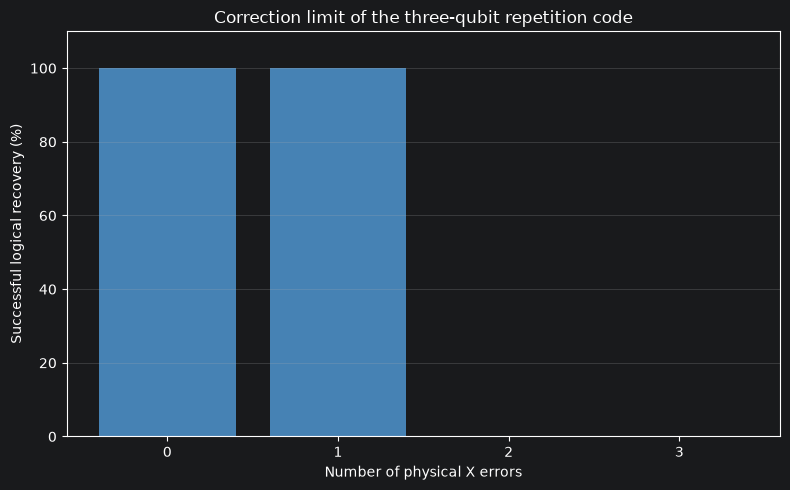

Saved figure to: C:\Users\Karthi\Qauntum\figures\repetition_code_correction_limit.png


In [69]:
# Plot correction success by error weight
figure, axis = plt.subplots(
    figsize=(8, 5)
)

axis.bar(
    error_weight_summary[
        "number_of_errors"
    ],
    100.0
    * error_weight_summary[
        "success_rate"
    ],
    color=[
        "steelblue",
        "steelblue",
        "darkred",
        "darkred",
    ],
)

axis.set_xlabel(
    "Number of physical X errors"
)

axis.set_ylabel(
    "Successful logical recovery (%)"
)

axis.set_title(
    "Correction limit of the three-qubit "
    "repetition code"
)

axis.set_xticks(
    [0, 1, 2, 3]
)

axis.set_ylim(
    0,
    110,
)

axis.grid(
    axis="y",
    alpha=0.3,
)

figure.tight_layout()

correction_limit_figure_path = (
    FIGURE_DIR
    / "repetition_code_correction_limit.png"
)

figure.savefig(
    correction_limit_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{correction_limit_figure_path}"
)

In [70]:
# Examine syndrome ambiguity
syndrome_ambiguity_df = (
    logical_zero_multiple_error_df[
        [
            "error_qubits",
            "number_of_errors",
            "syndrome",
            "corrected_data",
            "correction_successful",
        ]
    ]
    .sort_values(
        [
            "syndrome",
            "number_of_errors",
        ]
    )
    .reset_index(
        drop=True
    )
)

syndrome_ambiguity_df

,error_qubits,number_of_errors,syndrome,corrected_data,correction_successful
0,none,0,00,000,True
1,"q0, q1, q2",3,00,111,False
2,q0,1,01,000,True
3,"q1, q2",2,01,111,False
4,q2,1,10,000,True
5,"q0, q1",2,10,111,False
6,q1,1,11,000,True
7,"q0, q2",2,11,111,False


In [71]:
# Group errors by syndrome
for syndrome, group in (
    syndrome_ambiguity_df.groupby(
        "syndrome"
    )
):
    print(f"Syndrome {syndrome}:")

    for row in group.to_dict(
        orient="records"
    ):
        print(
            f"  Errors: "
            f"{row['error_qubits']:<10} | "
            f"Weight: "
            f"{row['number_of_errors']} | "
            f"Success: "
            f"{row['correction_successful']}"
        )

Syndrome 00:
  Errors: none       | Weight: 0 | Success: True
  Errors: q0, q1, q2 | Weight: 3 | Success: False
Syndrome 01:
  Errors: q0         | Weight: 1 | Success: True
  Errors: q1, q2     | Weight: 2 | Success: False
Syndrome 10:
  Errors: q2         | Weight: 1 | Success: True
  Errors: q0, q1     | Weight: 2 | Success: False
Syndrome 11:
  Errors: q1         | Weight: 1 | Success: True
  Errors: q0, q2     | Weight: 2 | Success: False


In [72]:
# Saving datasets
multiple_error_results_path = (
    RESULTS_DIR
    / "repetition_code_multiple_errors.csv"
)

multiple_error_results_df.to_csv(
    multiple_error_results_path,
    index=False,
)

error_weight_summary_path = (
    RESULTS_DIR
    / "repetition_code_error_weight_summary.csv"
)

error_weight_summary.to_csv(
    error_weight_summary_path,
    index=False,
)

syndrome_ambiguity_path = (
    RESULTS_DIR
    / "repetition_code_syndrome_ambiguity.csv"
)

syndrome_ambiguity_df.to_csv(
    syndrome_ambiguity_path,
    index=False,
)

print(
    f"Saved full results to: "
    f"{multiple_error_results_path}"
)

print(
    f"Saved error-weight summary to: "
    f"{error_weight_summary_path}"
)

print(
    f"Saved syndrome ambiguity table to: "
    f"{syndrome_ambiguity_path}"
)

Saved full results to: C:\Users\Karthi\Qauntum\results\repetition_code_multiple_errors.csv
Saved error-weight summary to: C:\Users\Karthi\Qauntum\results\repetition_code_error_weight_summary.csv
Saved syndrome ambiguity table to: C:\Users\Karthi\Qauntum\results\repetition_code_syndrome_ambiguity.csv


## Correction-Limit Results

The three-qubit repetition code corrected all error patterns of Hamming weight $w = 0$ or $w = 1$, and failed for every tested error pattern of weight $w = 2$ or $w = 3$.

This behaviour follows directly from the code distance $d = 3$. A distance-$d$ stabiliser code can correct at most

$$t = \left\lfloor \frac{d - 1}{2} \right\rfloor = 1$$

single-qubit error.

The measured syndrome $s_1 s_0$ does not uniquely identify the physical error pattern. For example, syndrome $01$ can be produced either by a single error on $q_0$ ($X_0$) or by simultaneous errors on $q_1$ and $q_2$ ($X_1 X_2$). The decoder selects the single-qubit recovery ($X_0$) because it is the lowest-weight explanation consistent with the observed syndrome.

When two qubits have actually flipped (e.g., $X_1 X_2$), this minimum-weight recovery acts on the remaining unflipped qubit ($X_0$). Consequently, all three physical qubits end up flipped ($X_0 X_1 X_2 = X_L$), transforming the state into the opposite logical codeword ($\lvert 0_L \rangle \leftrightarrow \lvert 1_L \rangle$) and producing a logical failure.

When all three qubits flip ($X_0 X_1 X_2$), their pairwise parity relationships ($Z_0 Z_1$ and $Z_1 Z_2$) remain unchanged. The measured syndrome is therefore $00$, identical to the no-error ($I$) syndrome. No correction is applied, and the opposite logical codeword remains.

This illustrates a fundamental property of syndrome decoding: a syndrome identifies an equivalence class (coset) of errors rather than uniquely specifying the physical fault. Successful decoding relies on selecting the most probable recovery operator from that coset under an assumed physical noise model (such as independent, low-rate bit-flip noise with $p < 0.5$).


# Physical and Logical Error Probabilities

Each physical qubit is assumed to experience an independent bit-flip ($X$) error with probability $p$.

An unencoded bit fails with probability:

$$P_{\text{physical}} = p$$

The three-qubit repetition code fails when at least two of its three physical qubits flip ($w \ge 2$). Its theoretical logical failure probability is therefore:

$$\begin{aligned}
P_{\text{logical}} &= \binom{3}{2} p^2 (1 - p) + \binom{3}{3} p^3 \\
&= 3p^2(1 - p) + p^3 \\
&= 3p^2 - 2p^3
\end{aligned}$$

The first term ($3p^2(1 - p)$) represents weight-$2$ errors (exactly two flips), while the second term ($p^3$) represents weight-$3$ errors (all three qubits flipping). Notice that the code suppresses logical errors ($P_{\text{logical}} < p$) whenever $p < 0.5$.

This experiment uses Monte Carlo sampling to estimate $P_{\text{logical}}$ empirically and compare it with the analytical curve.


In [73]:
# Analytical failure function
# Return the logical failure probability of the three-qubit repetition code under independent bit-flip noise
def theoretical_logical_failure_probability(
    physical_error_probability,
):

    p = np.asarray(
        physical_error_probability,
        dtype=float,
    )

    if np.any((p < 0.0) | (p > 1.0)):
        raise ValueError(
            "Physical error probabilities must be between 0 and 1"
        )

    return 3.0 * p**2 - 2.0 * p**3

In [74]:
assert np.isclose(
    theoretical_logical_failure_probability(0.0),
    0.0,
)

assert np.isclose(
    theoretical_logical_failure_probability(0.5),
    0.5,
)

assert np.isclose(
    theoretical_logical_failure_probability(1.0),
    1.0,
)

print(
    "The analytical logical-failure function passed its basic tests."
)

The analytical logical-failure function passed its basic tests.


In [75]:
# Implement single Monte Carlo experiment
# Estimate logical failure probability for the three-qubit repetition code
# Simulation samples physical errors directly, rather than executing a separate Qiskit circuit for every trial
# Each trial samples three independent physical bit-flip errors. Logical failure occurs when at least two physical qubits flip.
def simulate_repetition_code_failures(
    physical_error_probability,
    number_of_trials,
    seed=None,
):

    p = float(
        physical_error_probability
    )

    if not 0.0 <= p <= 1.0:
        raise ValueError(
            "physical_error_probability must be between 0 and 1."
        )

    if number_of_trials <= 0:
        raise ValueError(
            "number_of_trials must be positive."
        )

    rng = np.random.default_rng(
        seed
    )

    physical_errors = rng.random(
        size=(
            number_of_trials,
            3,
        )
    ) < p

    error_weights = physical_errors.sum(
        axis=1
    )

    logical_failures = (
        error_weights >= 2
    )

    number_of_logical_failures = int(
        logical_failures.sum()
    )

    logical_failure_probability = (
        number_of_logical_failures
        / number_of_trials
    )

    return {
        "physical_error_probability": p,
        "number_of_trials": number_of_trials,
        "logical_failures": (
            number_of_logical_failures
        ),
        "logical_failure_probability": (
            logical_failure_probability
        ),
        "mean_error_weight": float(
            error_weights.mean()
        ),
    }

In [76]:
# Test single error probability
test_probability = 0.05
test_trials = 100_000

test_result = (
    simulate_repetition_code_failures(
        physical_error_probability=(
            test_probability
        ),
        number_of_trials=test_trials,
        seed=SEED,
    )
)

theoretical_test_probability = (
    theoretical_logical_failure_probability(
        test_probability
    )
)

print(
    f"Physical error probability: "
    f"{test_probability:.4%}"
)

print(
    f"Simulated logical failure probability: "
    f"{test_result['logical_failure_probability']:.4%}"
)

print(
    f"Theoretical logical failure probability: "
    f"{theoretical_test_probability:.4%}"
)

print(
    f"Observed logical failures: "
    f"{test_result['logical_failures']:,}"
)

Physical error probability: 5.0000%
Simulated logical failure probability: 0.7060%
Theoretical logical failure probability: 0.7250%
Observed logical failures: 706


In [77]:
# Calculate statistical uncertainty
# Return the binomial standard error
def binomial_standard_error(
    estimated_probability,
    number_of_trials,
):

    probability = float(
        estimated_probability
    )

    return np.sqrt(
        probability
        * (1.0 - probability)
        / number_of_trials
    )

In [78]:
test_standard_error = (
    binomial_standard_error(
        test_result[
            "logical_failure_probability"
        ],
        test_trials,
    )
)

test_lower_bound = max(
    0.0,
    test_result[
        "logical_failure_probability"
    ]
    - 1.96 * test_standard_error,
)

test_upper_bound = min(
    1.0,
    test_result[
        "logical_failure_probability"
    ]
    + 1.96 * test_standard_error,
)

print(
    f"Approximate 95% interval: "
    f"[{test_lower_bound:.4%}, "
    f"{test_upper_bound:.4%}]"
)

Approximate 95% interval: [0.6541%, 0.7579%]


In [79]:
# Sweep the physical error probability
# Using denser set of values low probabilities
physical_error_probabilities = np.array(
    [
        0.001,
        0.002,
        0.005,
        0.010,
        0.020,
        0.030,
        0.050,
        0.075,
        0.100,
        0.150,
        0.200,
        0.300,
        0.400,
        0.500,
    ],
    dtype=float,
)

number_of_trials = 500_000

In [80]:
# Run sweep
logical_error_results = []

for index, physical_probability in enumerate(
    physical_error_probabilities
):
    result = simulate_repetition_code_failures(
        physical_error_probability=(
            physical_probability
        ),
        number_of_trials=number_of_trials,
        seed=SEED + index,
    )

    simulated_logical_probability = result[
        "logical_failure_probability"
    ]

    theoretical_logical_probability = float(
        theoretical_logical_failure_probability(
            physical_probability
        )
    )

    standard_error = (
        binomial_standard_error(
            simulated_logical_probability,
            number_of_trials,
        )
    )

    logical_error_results.append(
        {
            "physical_error_probability": (
                physical_probability
            ),
            "unencoded_failure_probability": (
                physical_probability
            ),
            "simulated_logical_failure_probability": (
                simulated_logical_probability
            ),
            "theoretical_logical_failure_probability": (
                theoretical_logical_probability
            ),
            "logical_failure_count": result[
                "logical_failures"
            ],
            "number_of_trials": (
                number_of_trials
            ),
            "standard_error": (
                standard_error
            ),
            "confidence_interval_lower": max(
                0.0,
                simulated_logical_probability
                - 1.96 * standard_error,
            ),
            "confidence_interval_upper": min(
                1.0,
                simulated_logical_probability
                + 1.96 * standard_error,
            ),
            "mean_error_weight": result[
                "mean_error_weight"
            ],
        }
    )

    print(
        f"Physical p: "
        f"{physical_probability:7.3%} | "
        f"Simulated logical: "
        f"{simulated_logical_probability:8.4%} | "
        f"Theoretical logical: "
        f"{theoretical_logical_probability:8.4%} | "
        f"Failures: "
        f"{result['logical_failures']:7,d}"
    )

Physical p:  0.100% | Simulated logical:  0.0000% | Theoretical logical:  0.0003% | Failures:       0
Physical p:  0.200% | Simulated logical:  0.0004% | Theoretical logical:  0.0012% | Failures:       2
Physical p:  0.500% | Simulated logical:  0.0058% | Theoretical logical:  0.0075% | Failures:      29
Physical p:  1.000% | Simulated logical:  0.0270% | Theoretical logical:  0.0298% | Failures:     135
Physical p:  2.000% | Simulated logical:  0.1170% | Theoretical logical:  0.1184% | Failures:     585
Physical p:  3.000% | Simulated logical:  0.2612% | Theoretical logical:  0.2646% | Failures:   1,306
Physical p:  5.000% | Simulated logical:  0.7180% | Theoretical logical:  0.7250% | Failures:   3,590
Physical p:  7.500% | Simulated logical:  1.6102% | Theoretical logical:  1.6031% | Failures:   8,051
Physical p: 10.000% | Simulated logical:  2.7890% | Theoretical logical:  2.8000% | Failures:  13,945
Physical p: 15.000% | Simulated logical:  6.0370% | Theoretical logical:  6.0750% 

In [81]:
# Table conversion
logical_error_df = pd.DataFrame(
    logical_error_results
)

logical_error_df[
    [
        "physical_error_probability",
        "simulated_logical_failure_probability",
        "theoretical_logical_failure_probability",
        "standard_error",
        "logical_failure_count",
    ]
]

,physical_error_probability,simulated_logical_failure_probability,theoretical_logical_failure_probability,standard_error,logical_failure_count
0,0.001,0.000000,0.000003,0.000000,0
1,0.002,0.000004,0.000012,0.000003,2
2,0.005,0.000058,0.000075,0.000011,29
3,0.010,0.000270,0.000298,0.000023,135
4,0.020,0.001170,0.001184,0.000048,585
5,0.030,0.002612,0.002646,0.000072,1306
6,0.050,0.007180,0.007250,0.000119,3590
7,0.075,0.016102,0.016031,0.000178,8051
8,0.100,0.027890,0.028000,0.000233,13945
9,0.150,0.060370,0.060750,0.000337,30185


In [82]:
# Compare simulation with theory
# Calculate the absolute difference
logical_error_df[
    "absolute_simulation_error"
] = (
    logical_error_df[
        "simulated_logical_failure_probability"
    ]
    - logical_error_df[
        "theoretical_logical_failure_probability"
    ]
).abs()

In [83]:
# Calculate the difference in standard-error units
logical_error_df[
    "difference_in_standard_errors"
] = np.where(
    logical_error_df[
        "standard_error"
    ] > 0.0,
    logical_error_df[
        "absolute_simulation_error"
    ]
    / logical_error_df[
        "standard_error"
    ],
    0.0,
)

logical_error_df[
    [
        "physical_error_probability",
        "absolute_simulation_error",
        "difference_in_standard_errors",
    ]
]

,physical_error_probability,absolute_simulation_error,difference_in_standard_errors
0,0.001,0.000003,0.000000
1,0.002,0.000008,2.822776
2,0.005,0.000017,1.555244
3,0.010,0.000028,1.205091
4,0.020,0.000014,0.289584
5,0.030,0.000034,0.471026
6,0.050,0.000070,0.586254
7,0.075,0.000071,0.397463
8,0.100,0.000110,0.472385
9,0.150,0.000380,1.128183


In [84]:
# Broader validation
maximum_standard_error_difference = (
    logical_error_df[
        "difference_in_standard_errors"
    ].max()
)

print(
    "Largest simulation-theory difference: "
    f"{maximum_standard_error_difference:.2f} "
    "standard errors"
)

assert maximum_standard_error_difference < 5.0

print(
    "The simulations are statistically consistent with the analytical model."
)

Largest simulation-theory difference: 2.82 standard errors
The simulations are statistically consistent with the analytical model.


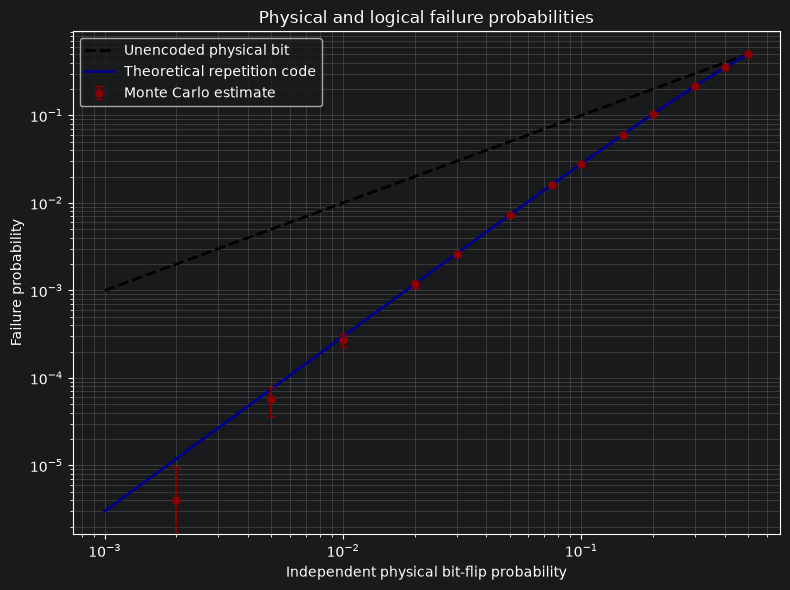

Saved figure to: C:\Users\Karthi\Qauntum\figures\physical_vs_logical_error_probability.png


In [85]:
# Plot physical and logical failure probabilities with a logarithmic scale so the low-error behaviour is visible
figure, axis = plt.subplots(
    figsize=(8, 6)
)

axis.plot(
    logical_error_df[
        "physical_error_probability"
    ],
    logical_error_df[
        "unencoded_failure_probability"
    ],
    linestyle="--",
    linewidth=2,
    color="black",
    label="Unencoded physical bit",
)

axis.plot(
    logical_error_df[
        "physical_error_probability"
    ],
    logical_error_df[
        "theoretical_logical_failure_probability"
    ],
    linewidth=2,
    color="darkblue",
    label="Theoretical repetition code",
)

axis.errorbar(
    logical_error_df[
        "physical_error_probability"
    ],
    logical_error_df[
        "simulated_logical_failure_probability"
    ],
    yerr=(
        1.96
        * logical_error_df[
            "standard_error"
        ]
    ),
    fmt="o",
    markersize=5,
    capsize=3,
    color="darkred",
    label="Monte Carlo estimate",
)

axis.set_xscale("log")
axis.set_yscale("log")

axis.set_xlabel(
    "Independent physical bit-flip probability"
)

axis.set_ylabel(
    "Failure probability"
)

axis.set_title(
    "Physical and logical failure probabilities"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

logical_error_figure_path = (
    FIGURE_DIR
    / "physical_vs_logical_error_probability.png"
)

figure.savefig(
    logical_error_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{logical_error_figure_path}"
)

In [86]:
# Plot the error-suppression factor
logical_error_df[
    "theoretical_suppression_factor"
] = (
    logical_error_df[
        "physical_error_probability"
    ]
    / logical_error_df[
        "theoretical_logical_failure_probability"
    ]
)

logical_error_df[
    "simulated_suppression_factor"
] = (
    logical_error_df[
        "physical_error_probability"
    ]
    / logical_error_df[
        "simulated_logical_failure_probability"
    ].replace(0.0, np.nan)
)

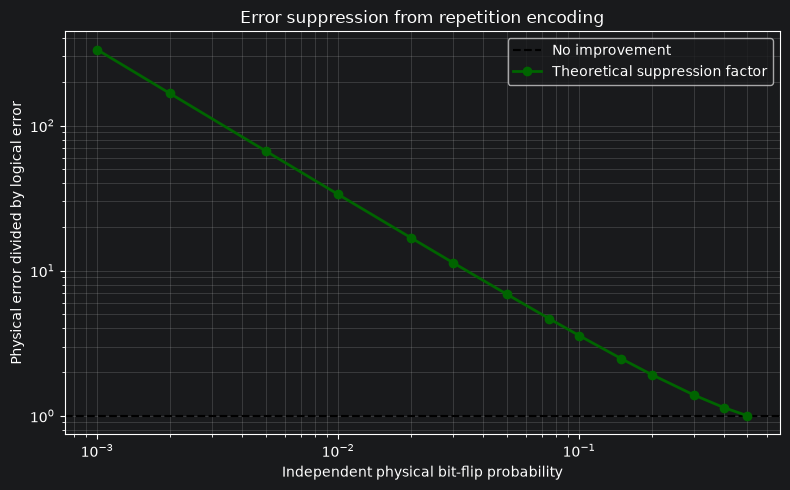

Saved figure to: C:\Users\Karthi\Qauntum\figures\repetition_code_error_suppression.png


In [87]:
figure, axis = plt.subplots(
    figsize=(8, 5)
)

axis.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="No improvement",
)

axis.plot(
    logical_error_df[
        "physical_error_probability"
    ],
    logical_error_df[
        "theoretical_suppression_factor"
    ],
    marker="o",
    linewidth=2,
    color="darkgreen",
    label="Theoretical suppression factor",
)

axis.set_xscale("log")
axis.set_yscale("log")

axis.set_xlabel(
    "Independent physical bit-flip probability"
)

axis.set_ylabel(
    "Physical error divided by logical error"
)

axis.set_title(
    "Error suppression from repetition encoding"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

suppression_figure_path = (
    FIGURE_DIR
    / "repetition_code_error_suppression.png"
)

figure.savefig(
    suppression_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{suppression_figure_path}"
)

In [88]:
example_probabilities = [
    0.01,
    0.05,
    0.10,
]

for physical_probability in example_probabilities:
    logical_probability = float(
        theoretical_logical_failure_probability(
            physical_probability
        )
    )

    suppression_factor = (
        physical_probability
        / logical_probability
    )

    print(
        f"p = {physical_probability:.1%} | "
        f"logical failure = "
        f"{logical_probability:.4%} | "
        f"suppression factor = "
        f"{suppression_factor:.2f}"
    )

p = 1.0% | logical failure = 0.0298% | suppression factor = 33.56
p = 5.0% | logical failure = 0.7250% | suppression factor = 6.90
p = 10.0% | logical failure = 2.8000% | suppression factor = 3.57


In [89]:
# Verify the crossover point
crossover_probability = 0.5

crossover_logical_probability = float(
    theoretical_logical_failure_probability(
        crossover_probability
    )
)

print(
    f"At p = {crossover_probability:.1%}:"
)

print(
    f"Physical failure probability: "
    f"{crossover_probability:.1%}"
)

print(
    f"Logical failure probability: "
    f"{crossover_logical_probability:.1%}"
)

assert np.isclose(
    crossover_probability,
    crossover_logical_probability,
)

At p = 50.0%:
Physical failure probability: 50.0%
Logical failure probability: 50.0%


In [90]:
# Save
logical_error_results_path = (
    RESULTS_DIR
    / "repetition_code_logical_error_sweep.csv"
)

logical_error_df.to_csv(
    logical_error_results_path,
    index=False,
)

print(
    f"Saved results to: "
    f"{logical_error_results_path}"
)

Saved results to: C:\Users\Karthi\Qauntum\results\repetition_code_logical_error_sweep.csv


## Logical-Error Simulation Results

The Monte Carlo simulation agreed with the analytical logical-failure probability:

$$P_{\text{logical}} = 3p^2 - 2p^3$$

Logical failure occurred whenever two or three of the physical bits flipped ($w \in \{2, 3\}$).

At low physical error probabilities ($p \ll 1$), the logical error probability scales approximately as $P_{\text{logical}} \approx 3p^2$. The cubic term ($-2p^3$) becomes relatively small, so the repetition code changes the leading error dependence from first order ($\mathcal{O}(p)$) to second order ($\mathcal{O}(p^2)$).

For example, a physical error probability of $p = 5\%$ ($0.05$) gives a theoretical logical failure probability of

$$P_{\text{logical}} = 3(0.05)^2 - 2(0.05)^3 = 0.00725 \quad (0.725\%)$$

corresponding to an error-suppression factor of $p / P_{\text{logical}} \approx 6.9$.

The repetition code improves reliability when the independent physical bit-flip probability is below the threshold $p < 50\%$ ($0.5$). At $p = 50\%$, the physical and logical failure probabilities are equal ($P_{\text{logical}} = P_{\text{physical}} = 0.5$). Above $50\%$, majority voting is more likely to select the wrong logical value ($P_{\text{logical}} > p$).

The simulation assumes independent and identically distributed (i.i.d.) bit flips. It also assumes fault-free encoding, syndrome extraction, and recovery. A realistic circuit-level quantum error-correction simulation must account for faults introduced by $\text{CNOT}$ gates, ancilla preparation, measurement, and the recovery procedure itself.

The experiment also demonstrates why rare logical failures are computationally expensive to estimate directly. Because the standard error scales as $\sigma \approx \sqrt{P_{\text{logical}} / N}$, progressively more Monte Carlo shots ($N \propto 1 / p^2$) are required as $p$ decreases in order to observe enough logical failures for a precise estimate.


# Monte Carlo Convergence and Rare-Event Estimation

Logical failure probabilities are commonly estimated by repeatedly sampling physical errors over $N$ shots and counting the resulting number of logical failures, $k$.

For $N$ independent Bernoulli trials with estimated failure probability $\hat{p} = k / N$, the approximate standard error is:

$$\text{SE}(\hat{p}) = \sqrt{\frac{\hat{p}(1 - \hat{p})}{N}}$$

The relative standard error is:

$$\text{RSE}(\hat{p}) = \frac{\text{SE}(\hat{p})}{\hat{p}} = \sqrt{\frac{1 - \hat{p}}{N\hat{p}}}$$

For rare failures ($\hat{p} \ll 1$, so $1 - \hat{p} \approx 1$), substituting $N\hat{p} = k$ shows that the relative uncertainty simplifies to:

$$\text{RSE}(\hat{p}) \approx \frac{1}{\sqrt{k}}$$

where $k$ is the number of observed logical failures. This means that the statistical precision of a Monte Carlo estimate depends primarily on how many failure events are observed, rather than on the total number of trials $N$ alone.


In [91]:
# repeated-experiment function
# Repeat the repetition-code Monte Carlo simulation using independent random-number streams
def repeat_logical_failure_experiment(
    physical_error_probability,
    number_of_trials,
    number_of_repeats,
    seed=SEED,
):


    if number_of_repeats <= 0:
        raise ValueError(
            "number_of_repeats must be positive."
        )

    repeated_results = []

    for repeat_index in range(
        number_of_repeats
    ):
        result = (
            simulate_repetition_code_failures(
                physical_error_probability=(
                    physical_error_probability
                ),
                number_of_trials=(
                    number_of_trials
                ),
                seed=seed + repeat_index,
            )
        )

        repeated_results.append(
            {
                "repeat": repeat_index,
                "physical_error_probability": (
                    physical_error_probability
                ),
                "number_of_trials": (
                    number_of_trials
                ),
                "logical_failures": result[
                    "logical_failures"
                ],
                "logical_failure_probability": (
                    result[
                        "logical_failure_probability"
                    ]
                ),
            }
        )

    return pd.DataFrame(
        repeated_results
    )

In [92]:
# Convergence with increasing trial count
# choosing a physical bit-flip probability of p = 0.02
convergence_physical_probability = 0.02

convergence_theoretical_probability = float(
    theoretical_logical_failure_probability(
        convergence_physical_probability
    )
)

print(
    "Physical error probability: "
    f"{convergence_physical_probability:.4%}"
)

print(
    "Theoretical logical failure probability: "
    f"{convergence_theoretical_probability:.6%}"
)

Physical error probability: 2.0000%
Theoretical logical failure probability: 0.118400%


In [93]:
# Repeat several trial counts
trial_counts = [
    1_000,
    3_000,
    10_000,
    30_000,
    100_000,
    300_000,
]

number_of_repeats = 50

convergence_results = []

In [94]:
# Run
for trial_count_index, trial_count in enumerate(
    trial_counts
):
    repeated_df = (
        repeat_logical_failure_experiment(
            physical_error_probability=(
                convergence_physical_probability
            ),
            number_of_trials=trial_count,
            number_of_repeats=number_of_repeats,
            seed=(
                SEED
                + trial_count_index * 10_000
            ),
        )
    )

    repeated_df[
        "theoretical_logical_probability"
    ] = convergence_theoretical_probability

    convergence_results.append(
        repeated_df
    )

    print(
        f"Trials per repeat: "
        f"{trial_count:>7,d} | "
        f"Mean estimate: "
        f"{repeated_df['logical_failure_probability'].mean():.6%} | "
        f"Standard deviation: "
        f"{repeated_df['logical_failure_probability'].std(ddof=1):.6%}"
    )

Trials per repeat:   1,000 | Mean estimate: 0.104000% | Standard deviation: 0.085619%
Trials per repeat:   3,000 | Mean estimate: 0.123333% | Standard deviation: 0.078028%
Trials per repeat:  10,000 | Mean estimate: 0.102800% | Standard deviation: 0.028929%
Trials per repeat:  30,000 | Mean estimate: 0.111133% | Standard deviation: 0.020709%
Trials per repeat: 100,000 | Mean estimate: 0.118240% | Standard deviation: 0.010914%
Trials per repeat: 300,000 | Mean estimate: 0.118853% | Standard deviation: 0.005716%


In [95]:
convergence_df = pd.concat(
    convergence_results,
    ignore_index=True,
)

convergence_df.head()

,repeat,physical_error_probability,number_of_trials,logical_failures,logical_failure_probability,theoretical_logical_probability
0,0,0.02,1000,1,0.001,0.001184
1,1,0.02,1000,2,0.002,0.001184
2,2,0.02,1000,1,0.001,0.001184
3,3,0.02,1000,1,0.001,0.001184
4,4,0.02,1000,1,0.001,0.001184


In [96]:
# Summarise the convergence
convergence_summary_df = (
    convergence_df
    .groupby("number_of_trials")
    .agg(
        mean_estimate=(
            "logical_failure_probability",
            "mean",
        ),
        measured_standard_deviation=(
            "logical_failure_probability",
            "std",
        ),
        minimum_estimate=(
            "logical_failure_probability",
            "min",
        ),
        maximum_estimate=(
            "logical_failure_probability",
            "max",
        ),
        mean_failure_count=(
            "logical_failures",
            "mean",
        ),
        zero_failure_repeats=(
            "logical_failures",
            lambda values: int(
                (values == 0).sum()
            ),
        ),
    )
    .reset_index()
)

In [97]:
# Theoretical standard error
convergence_summary_df[
    "theoretical_standard_error"
] = np.sqrt(
    convergence_theoretical_probability
    * (
        1.0
        - convergence_theoretical_probability
    )
    / convergence_summary_df[
        "number_of_trials"
    ]
)

convergence_summary_df[
    "relative_standard_error"
] = (
    convergence_summary_df[
        "theoretical_standard_error"
    ]
    / convergence_theoretical_probability
)

convergence_summary_df

,number_of_trials,mean_estimate,measured_standard_deviation,minimum_estimate,maximum_estimate,mean_failure_count,zero_failure_repeats,theoretical_standard_error,relative_standard_error
0,1000,0.001040,0.000856,0.000000,0.003000,1.04,14,0.001087,0.918474
1,3000,0.001233,0.000780,0.000000,0.003667,3.70,3,0.000628,0.530281
2,10000,0.001028,0.000289,0.000400,0.001800,10.28,0,0.000344,0.290447
3,30000,0.001111,0.000207,0.000700,0.001733,33.34,0,0.000199,0.167690
4,100000,0.001182,0.000109,0.000900,0.001490,118.24,0,0.000109,0.091847
5,300000,0.001189,0.000057,0.001047,0.001343,356.56,0,0.000063,0.053028


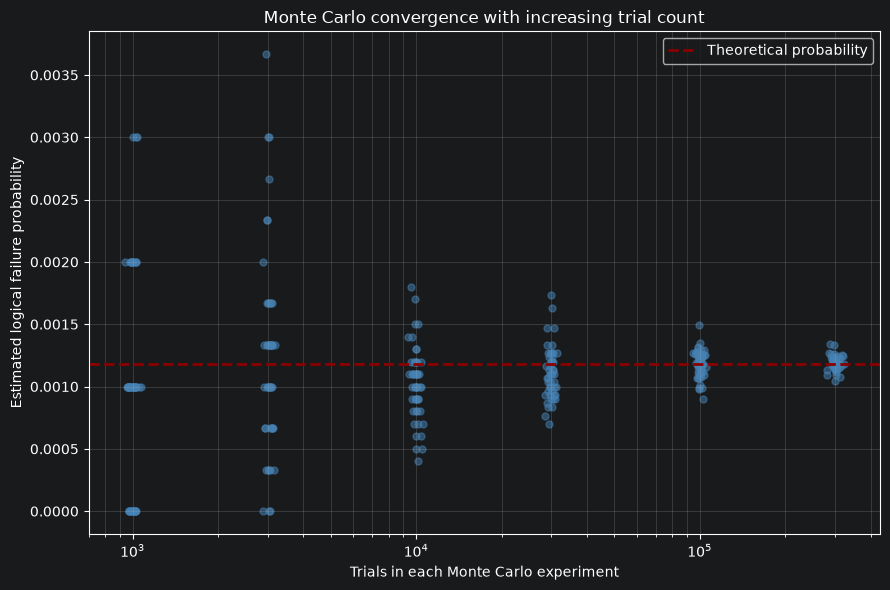

Saved figure to: C:\Users\Karthi\Qauntum\figures\monte_carlo_convergence_scatter.png


In [98]:
# Plot repeated estimates
figure, axis = plt.subplots(
    figsize=(9, 6)
)

for trial_count in trial_counts:
    subset = convergence_df[
        convergence_df[
            "number_of_trials"
        ] == trial_count
    ]

    x_values = np.full(
        len(subset),
        trial_count,
        dtype=float,
    )

    rng = np.random.default_rng(
        SEED + trial_count
    )

    jitter = np.exp(
        rng.normal(
            loc=0.0,
            scale=0.025,
            size=len(subset),
        )
    )

    axis.scatter(
        x_values * jitter,
        subset[
            "logical_failure_probability"
        ],
        alpha=0.5,
        s=25,
        color="steelblue",
    )

axis.axhline(
    convergence_theoretical_probability,
    color="darkred",
    linestyle="--",
    linewidth=2,
    label="Theoretical probability",
)

axis.set_xscale("log")
axis.set_xlabel(
    "Trials in each Monte Carlo experiment"
)
axis.set_ylabel(
    "Estimated logical failure probability"
)
axis.set_title(
    "Monte Carlo convergence with increasing trial count"
)
axis.grid(
    True,
    which="both",
    alpha=0.3,
)
axis.legend()

figure.tight_layout()

convergence_scatter_path = (
    FIGURE_DIR
    / "monte_carlo_convergence_scatter.png"
)

figure.savefig(
    convergence_scatter_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{convergence_scatter_path}"
)

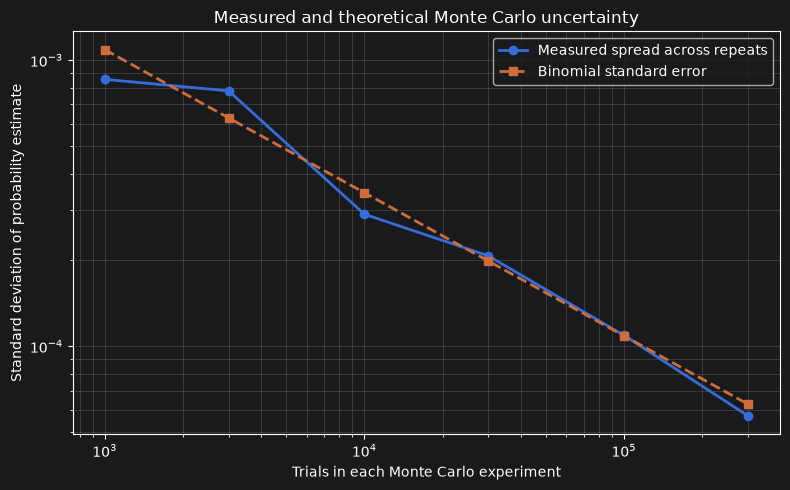

Saved figure to: C:\Users\Karthi\Qauntum\figures\monte_carlo_uncertainty_scaling.png


In [99]:
# Plot measured and predicted uncertainty
figure, axis = plt.subplots(
    figsize=(8, 5)
)

axis.plot(
    convergence_summary_df[
        "number_of_trials"
    ],
    convergence_summary_df[
        "measured_standard_deviation"
    ],
    marker="o",
    linewidth=2,
    label="Measured spread across repeats",
)

axis.plot(
    convergence_summary_df[
        "number_of_trials"
    ],
    convergence_summary_df[
        "theoretical_standard_error"
    ],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Binomial standard error",
)

axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel(
    "Trials in each Monte Carlo experiment"
)
axis.set_ylabel(
    "Standard deviation of probability estimate"
)
axis.set_title(
    "Measured and theoretical Monte Carlo uncertainty"
)
axis.grid(
    True,
    which="both",
    alpha=0.3,
)
axis.legend()

figure.tight_layout()

convergence_uncertainty_path = (
    FIGURE_DIR
    / "monte_carlo_uncertainty_scaling.png"
)

figure.savefig(
    convergence_uncertainty_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{convergence_uncertainty_path}"
)

In [100]:
# Calculate the number of trials required to observe a specified expected failure count
def trials_for_expected_failures(
    failure_probability,
    expected_failures,
):


    if not 0.0 < failure_probability <= 1.0:
        raise ValueError(
            "failure_probability must be greater than zero and no greater than one."
        )

    if expected_failures <= 0:
        raise ValueError(
            "expected_failures must be positive."
        )

    return int(
        np.ceil(
            expected_failures
            / failure_probability
        )
    )

In [101]:
# Rare-event table
rare_failure_probabilities = [
    1e-3,
    1e-6,
    1e-9,
    1e-12,
]

target_failure_counts = [
    1,
    10,
    100,
    10_000,
]

rare_event_requirements = []

for failure_probability in (
    rare_failure_probabilities
):
    for target_failures in (
        target_failure_counts
    ):
        required_trials = (
            trials_for_expected_failures(
                failure_probability,
                target_failures,
            )
        )

        approximate_relative_error = (
            1.0
            / np.sqrt(target_failures)
        )

        rare_event_requirements.append(
            {
                "failure_probability": (
                    failure_probability
                ),
                "target_expected_failures": (
                    target_failures
                ),
                "required_trials": (
                    required_trials
                ),
                "approximate_relative_error": (
                    approximate_relative_error
                ),
            }
        )

rare_event_requirements_df = pd.DataFrame(
    rare_event_requirements
)

rare_event_requirements_df

,failure_probability,target_expected_failures,required_trials,approximate_relative_error
0,1.000000e-03,1,1000,1.000000
1,1.000000e-03,10,10000,0.316228
2,1.000000e-03,100,100000,0.100000
3,1.000000e-03,10000,10000000,0.010000
4,1.000000e-06,1,1000000,1.000000
5,1.000000e-06,10,10000000,0.316228
6,1.000000e-06,100,100000000,0.100000
7,1.000000e-06,10000,10000000000,0.010000
8,1.000000e-09,1,1000000000,1.000000
9,1.000000e-09,10,10000000000,0.316228


In [102]:
simulation_rates = [
    1_000,
    1_000_000,
    1_000_000_000,
]

In [103]:
# Express a duration using an appropriate unit
def seconds_to_readable_time(seconds):

    if seconds < 60:
        return f"{seconds:.2f} seconds"

    minutes = seconds / 60

    if minutes < 60:
        return f"{minutes:.2f} minutes"

    hours = minutes / 60

    if hours < 24:
        return f"{hours:.2f} hours"

    days = hours / 24

    if days < 365.25:
        return f"{days:.2f} days"

    years = days / 365.25

    return f"{years:.2f} years"

In [104]:
# Evaluate
target_probability = 1e-12
target_failures = 100

required_trials = trials_for_expected_failures(
    target_probability,
    target_failures,
)

print(
    f"Required trials: "
    f"{required_trials:,}"
)

for simulation_rate in simulation_rates:
    required_seconds = (
        required_trials
        / simulation_rate
    )

    print(
        f"At {simulation_rate:,} trials/s: "
        f"{seconds_to_readable_time(required_seconds)}"
    )

Required trials: 100,000,000,000,000
At 1,000 trials/s: 3168.81 years
At 1,000,000 trials/s: 3.17 years
At 1,000,000,000 trials/s: 1.16 days


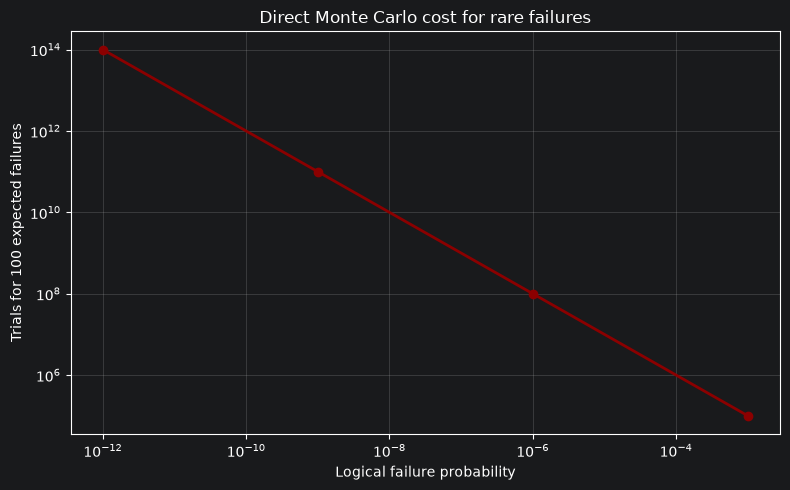

Saved figure to: C:\Users\Karthi\Qauntum\figures\rare_event_monte_carlo_cost.png


In [105]:
hundred_failure_rows = (
    rare_event_requirements_df[
        rare_event_requirements_df[
            "target_expected_failures"
        ] == 100
    ]
)

figure, axis = plt.subplots(
    figsize=(8, 5)
)

axis.loglog(
    hundred_failure_rows[
        "failure_probability"
    ],
    hundred_failure_rows[
        "required_trials"
    ],
    marker="o",
    linewidth=2,
    color="darkred",
)

axis.set_xlabel(
    "Logical failure probability"
)
axis.set_ylabel(
    "Trials for 100 expected failures"
)
axis.set_title(
    "Direct Monte Carlo cost for rare failures"
)
axis.grid(
    True,
    which="both",
    alpha=0.3,
)

figure.tight_layout()

rare_event_figure_path = (
    FIGURE_DIR
    / "rare_event_monte_carlo_cost.png"
)

figure.savefig(
    rare_event_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved figure to: "
    f"{rare_event_figure_path}"
)

In [106]:
# Return the probability of observing zero failures in independent Monte Carlo trials
def probability_of_zero_failures(
    failure_probability,
    number_of_trials,
):


    if not 0.0 <= failure_probability <= 1.0:
        raise ValueError(
            "failure_probability must be between zero and one."
        )

    if number_of_trials < 0:
        raise ValueError(
            "number_of_trials cannot be negative."
        )

    if failure_probability == 1.0:
        return 1.0 if number_of_trials == 0 else 0.0

    return float(
        np.exp(
            number_of_trials
            * np.log1p(
                -failure_probability
            )
        )
    )

In [107]:
zero_failure_examples = [
    100_000,
    1_000_000,
    3_000_000,
    10_000_000,
]

example_probability = 1e-6

for number_of_trials in zero_failure_examples:
    zero_probability = (
        probability_of_zero_failures(
            example_probability,
            number_of_trials,
        )
    )

    print(
        f"Trials: {number_of_trials:>10,d} | "
        f"Expected failures: "
        f"{number_of_trials * example_probability:7.2f} | "
        f"P(zero observed): "
        f"{zero_probability:.6%}"
    )

Trials:    100,000 | Expected failures:    0.10 | P(zero observed): 90.483737%
Trials:  1,000,000 | Expected failures:    1.00 | P(zero observed): 36.787926%
Trials:  3,000,000 | Expected failures:    3.00 | P(zero observed): 4.978699%
Trials: 10,000,000 | Expected failures:   10.00 | P(zero observed): 0.004540%


In [108]:
# Apply rule of three
# approximate 95% upper bound on failure probability after observing zero failures
def rule_of_three_upper_bound(
    number_of_trials,
):

    if number_of_trials <= 0:
        raise ValueError(
            "number_of_trials must be positive"
        )

    return 3.0 / number_of_trials

In [109]:
# Examples
zero_failure_trial_counts = [
    1_000,
    1_000_000,
    1_000_000_000,
    3_000_000_000_000,
]

for number_of_trials in (
    zero_failure_trial_counts
):
    upper_bound = (
        rule_of_three_upper_bound(
            number_of_trials
        )
    )

    print(
        f"Zero failures in "
        f"{number_of_trials:,} trials -> "
        f"approximate 95% upper bound: "
        f"{upper_bound:.3e}"
    )

Zero failures in 1,000 trials -> approximate 95% upper bound: 3.000e-03
Zero failures in 1,000,000 trials -> approximate 95% upper bound: 3.000e-06
Zero failures in 1,000,000,000 trials -> approximate 95% upper bound: 3.000e-09
Zero failures in 3,000,000,000,000 trials -> approximate 95% upper bound: 1.000e-12


In [110]:
# Save the results
# Export raw trial-by-trial estimates from repeated Monte Carlo experiments
convergence_results_path = (
    RESULTS_DIR
    / "monte_carlo_convergence_results.csv"
)

convergence_df.to_csv(
    convergence_results_path,
    index=False,
)
# Export aggregated convergence statistics
convergence_summary_path = (
    RESULTS_DIR
    / "monte_carlo_convergence_summary.csv"
)

convergence_summary_df.to_csv(
    convergence_summary_path,
    index=False,
)
# Export projected shot counts required for target relative precisions and Rule-of-Three bounds
rare_event_requirements_path = (
    RESULTS_DIR
    / "rare_event_sampling_requirements.csv"
)

rare_event_requirements_df.to_csv(
    rare_event_requirements_path,
    index=False,
)

# Confirm output file locations in the console
print(
    f"Saved repeated experiments to: "
    f"{convergence_results_path}"
)

print(
    f"Saved convergence summary to: "
    f"{convergence_summary_path}"
)

print(
    f"Saved rare-event requirements to: "
    f"{rare_event_requirements_path}"
)

Saved repeated experiments to: C:\Users\Karthi\Qauntum\results\monte_carlo_convergence_results.csv
Saved convergence summary to: C:\Users\Karthi\Qauntum\results\monte_carlo_convergence_summary.csv
Saved rare-event requirements to: C:\Users\Karthi\Qauntum\results\rare_event_sampling_requirements.csv


## Monte Carlo and Rare-Event Results

Repeated Monte Carlo experiments showed that empirical estimates became more tightly concentrated around the theoretical logical-failure probability $P_L$ as the number of trials $N$ increased. The measured spread followed the binomial standard error and scaled inversely with the square root of the sample size:

$$\sigma_{\hat{P}_L} = \sqrt{\frac{P_L(1 - P_L)}{N}} \propto \frac{1}{\sqrt{N}}$$

### Sample Size and Relative Precision
For rare events ($P_L \ll 1$), the relative statistical uncertainty is governed primarily by the number of observed failures $k \approx N P_L$:

$$\frac{\sigma_{\hat{P}_L}}{P_L} \approx \frac{1}{\sqrt{k}}$$

* **$\sim 10\%$ relative uncertainty:** Requires $k \approx 100$ observed failures.
* **$\sim 1\%$ relative uncertainty:** Requires $k \approx 10{,}000$ observed failures.

At a target fault-tolerant regime of $P_L = 10^{-12}$, direct Monte Carlo requires $N \approx 10^{14}$ trials just to observe $100$ expected failures—a computational cost that becomes prohibitive when each shot simulates multiple syndrome-extraction rounds and runs a non-trivial decoder.

### Zero-Failure Runs and the Rule of Three
Observing zero failures ($k = 0$) does not establish that $P_L = 0$. Under Poisson statistics, when the expected number of failures is $\lambda = N P_L = 1$, the probability of observing zero failures remains substantial:

$$P(k = 0 \mid \lambda = 1) = e^{-1} \approx 36.8\%$$

When no failures occur in $N$ independent trials, the **Rule of Three** provides an approximate $95\%$ upper confidence bound:

$$P_L \lesssim \frac{3}{N}$$

| Target Regime / Bound | Statistical Criterion | Required Trials ($N$) |
| :--- | :--- | :--- |
| $P_L = 10^{-12}$ ($\sim 10\%$ uncertainty) | $k \approx 100$ failures | $\sim 10^{14}$ |
| $P_L = 10^{-12}$ ($\sim 1\%$ uncertainty) | $k \approx 10{,}000$ failures | $\sim 10^{16}$ |
| $P_L \lesssim 10^{-12}$ ($95\%$ upper bound) | $k = 0$ failures ($3/N$) | $\sim 3 \times 10^{12}$ |

### Motivation for Rare-Event Methods
Because brute-force sampling wastes almost all computation on trivial, error-free shots, ultra-low logical error regimes motivate specialized rare-event techniques—including **importance sampling**, **multilevel splitting**, **targeted fault-pattern enumeration**, and **analytical bounds**—to estimate $P_L$ efficiently.
